#1. Определение статистик и построение тестов

#Тест на основе сериальной корреляции (Вальд и Вольфовиц)

Вычислим статистику $R$:
   $$
   R = \sum_{a=1}^{N-1} x_a \cdot x_{a+1} + x_N \cdot x_1 \quad (\text{сумма от } a=1 \text{ до } N-1)
   $$

   Тест (двусторонний) на основе сериальной корреляции можно записать в виде:

$$
\varphi(x_1, \ldots, x_n) =
\begin{cases}
1, & \text{если } |R| > C_{1-\alpha/2}, \\
0, & \text{если } |R| <= C_{1-\alpha/2},
\end{cases}
$$

где:
- $R = \sum_{a=1}^{N} x_a x_{a+1} + x_N x_1$ — тестовая статистика.
- $C_\alpha$ — критическое значение, выбранное так, чтобы $P_0(|R| > C_{1-\alpha/2}) = \alpha$, где $P_0$ — вероятность при истинности $H_0$.
- $\alpha$ — уровень значимости.

Критическая область $\mathcal{X}_1$ для теста на основе сериальной корреляции может быть записана как:

$$
\mathcal{X}_1 = \{ R : P_0(R \in \mathcal{X}_1) \leq \alpha \}
$$

Выбирается подмножество $M$ значений $R$ из всех возможных $N!$ значений, таких что:

$$
\frac{M}{N!} = \alpha
$$

где $M$ — количество значений $R$, входящих в критическую область.

Для измерения мощности теста в случае альтернативы линейного тренда можно использовать следующий подход:

1. Определим критическую область для теста. Для линейного тренда это будут $M$ наибольших значений $R$, где $\frac{M}{N!} = \alpha$ (уровень значимости).

2. Мощность теста $phi$ определяется как вероятность отклонения нулевой гипотезы при истинности альтернативной гипотезы о линейном тренде.

Данный подход применим в случае малых выборок.

При больших N применяется аппроксимация предельным нормальным распределением.

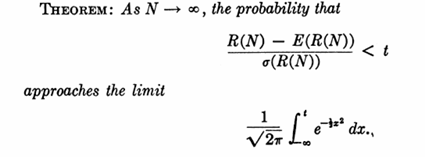

Алгоритм:

1) Вычисляем статистику R

2) Вычисляем матожидание и дисперсию

3) Стандартизируем значение R, чтобы использовать предельное нормальное распределение N(0, 1) по формуле

$$
Z = \frac{R_{\text{obs}} - E(R)}{\sigma(R)}
$$

Напишем функцию для вычисления тестовой статистики R

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats import chi2
from scipy.special import erf
import yfinance as yf
import pandas as pd
import datetime
np.random.seed(1291)

In [ ]:
def calculate_R(x):
    R = 0
    for i in range(len(x) - 1):
        R += x[i] * x[i + 1]
    R += x[-1] * x[0]
    return R

Формула матожидания:
$$
E(R) = \frac{S_1^2 - S_2}{N - 1}
$$

Формула дисперсии:
$$
\sigma^2(R) = \frac{S_2^2 - S_4}{N - 1} + \frac{S_1^4 - 4S_1^2S_2 + 4S_1S_3 + S_2^2 - 2S_4}{(N - 1)(N - 2)} - \frac{(S_1^2 - S_2)^2}{(N - 1)^2}.
$$

Где
$$
S_1 = \sum_{i=1}^N x_i,
$$

$$
S_2 = \sum_{i=1}^N x_i^2,
$$

$$
S_3 = \sum_{i=1}^N x_i^3,
$$

$$
S_4 = \sum_{i=1}^N x_i^4.
$$

Напишем функцию для вычисления матожидания и дисперсии статистики R

In [ ]:
def calculate_mean_variance(x):
    """
    Вычисляет математическое ожидание E(R) и дисперсию σ(R) для статистики R.
    """
    N = len(x)
    S1 = sum(x)
    S2 = sum(xi**2 for xi in x)
    S3 = sum(xi**3 for xi in x)
    S4 = sum(xi**4 for xi in x)

    # Математическое ожидание E(R)
    E_R = (S1**2-S2)/(N-1)

    # Дисперсия σ(R)
    var_R = (S2**2 - S4)/(N - 1) + (S1**4 - 4*(S1**2)*S2 + 4*S1*S3 + S2**2-2*S4)/((N-1)*(N-2)) - ((S1**2-S2)**2)/((N-1)**2)

    return E_R, var_R

Напишем функцию построения теста

In [ ]:
def serial_corr_test(data, alpha):
    N = len(data)

    R = calculate_R(data)

    E_R, var_R = calculate_mean_variance(data)

    std_R = np.sqrt(var_R)

    changed_R = (R - E_R) / std_R
    critical_value = norm.ppf(1 - alpha/2)

    if abs(changed_R) <= critical_value:
      return True
    else:
      return False

Напишем функцию вычисления мощности теста на основе сериальной корреляции

In [ ]:
def calculate_power_sc(data, alpha, num_of_runs):
    rejections = 0
    for i in range(num_of_runs):
      if serial_corr_test(data[i], alpha) == False:
        rejections += 1
    power = rejections / num_of_runs
    return power

#Ранговый тест RVN (статья Роберта Бартелса)

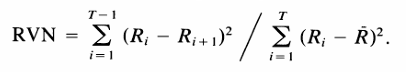

Нулевая гипотеза $H_0$: Последовательность случайна (независимые и одинаково распределенные значения).

Альтернативная гипотеза $H_1$: Последовательность имеет линейный тренд/периодичность/автокорреляцию.

Левосторонний тест

$$
\varphi(x_1, \ldots, x_n) =
\begin{cases}
1, & \text{если } RVN < C_\alpha, \\
0, & \text{если } RVN \geq C_\alpha.
\end{cases}
$$

- $RVN$ — тестовая статистика.
- $C_\alpha$ — критическое значение, выбранное так, чтобы $P_0(RVN < C_\alpha) = \alpha$.
- $\alpha$ — уровень значимости.

При T от 10 до 100 можно воспользоваться таблицей критических значений из статьи, при T>100 можно сделать аппроксимацию нормальным распределением N(2, 4/T).

Напишем функцию для вычисления рангов элементов выборки

In [ ]:
def calculate_ranks (X):
  indexes = {}
  ranks = {}
  X_sorted = sorted(X)
  if len(set(X)) == len(X):
    for x in X:
      index = X_sorted.index(x)
      indexes[x] = index + 1
  else:
    repeated_x = []
    i = 0
    while i < len(X_sorted):
      if X_sorted.count(X_sorted[i]) < 2:
        indexes[X_sorted[i]] = i + 1
      else:
        s = i + 1
        k = 1
        while i+1< len(X_sorted) and X_sorted[i+1] == X_sorted[i]:
          s += i + 1 + 1
          k += 1
          i += 1
        indexes[X_sorted[i]] = s/k
      i += 1
  for x in X:
    ranks[x] = indexes[x]
  return ranks

sequence = [6, 1, 2, 7, 8, 2, 100]
print(calculate_ranks(sequence))

{6: 4, 1: 1, 2: 2.5, 7: 5, 8: 6, 100: 7}


Напишем функцию для вычисления статистики ранговой версии теста

In [ ]:
def calculate_rvn(X):
  ranks = calculate_ranks(X)
  T = len(X)
  RVN = 0
  NM = 0
  denominator = 0
  R_ = np.mean(list(ranks.values()))
  for i in range (T - 1):
    NM += (ranks[X[i]] - ranks[X[i + 1]]) ** 2
    denominator += (ranks[X[i]] - R_) ** 2
  denominator += (ranks[X[T-1]] - R_) ** 2
  RVN = NM/denominator
  return RVN

Напишем функцию для вычисления мощности рангового теста

In [ ]:
def calculate_power_rvn(data, critical_value, num_of_runs):
    rejections = 0
    for i in range(num_of_runs):
      rvn = calculate_rvn(data[i])
      if rvn < critical_value:
        rejections += 1

    # Мощность теста
    power = rejections / num_of_runs
    return power

Составим таблицу критических значений (таблица 2 из статьи) для значений T от 10 до 100

In [ ]:
Ts = [10, 20, 30, 50, 60, 80, 90, 100, 140, 180, 200, 240, 260, 300]
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]

full_table = [
    [0.62, 0.72, 0.89, 1.04, 1.23],
    [0.94, 1.03, 1.17, 1.29, 1.44],
    [1.11, 1.19, 1.31, 1.41, 1.54],
    [1.29, 1.36, 1.46, 1.54, 1.64],
    [1.35, 1.41, 1.50, 1.58, 1.67],
    [1.44, 1.49, 1.57, 1.64, 1.71],
    [1.47, 1.52, 1.59, 1.66, 1.73],
    [1.49, 1.54, 1.61, 1.67, 1.74]
]


rvn_critical_values = {}
i = 0
while Ts[i]<=100:
    row = full_table[i]
    for j, alpha in enumerate(alphas):
        rvn_critical_values[(Ts[i], alpha)] = row[j]
    i += 1
print(rvn_critical_values)

{(10, 0.005): 0.62, (10, 0.01): 0.72, (10, 0.025): 0.89, (10, 0.05): 1.04, (10, 0.1): 1.23, (20, 0.005): 0.94, (20, 0.01): 1.03, (20, 0.025): 1.17, (20, 0.05): 1.29, (20, 0.1): 1.44, (30, 0.005): 1.11, (30, 0.01): 1.19, (30, 0.025): 1.31, (30, 0.05): 1.41, (30, 0.1): 1.54, (50, 0.005): 1.29, (50, 0.01): 1.36, (50, 0.025): 1.46, (50, 0.05): 1.54, (50, 0.1): 1.64, (60, 0.005): 1.35, (60, 0.01): 1.41, (60, 0.025): 1.5, (60, 0.05): 1.58, (60, 0.1): 1.67, (80, 0.005): 1.44, (80, 0.01): 1.49, (80, 0.025): 1.57, (80, 0.05): 1.64, (80, 0.1): 1.71, (90, 0.005): 1.47, (90, 0.01): 1.52, (90, 0.025): 1.59, (90, 0.05): 1.66, (90, 0.1): 1.73, (100, 0.005): 1.49, (100, 0.01): 1.54, (100, 0.025): 1.61, (100, 0.05): 1.67, (100, 0.1): 1.74}


#Критерий инверсий

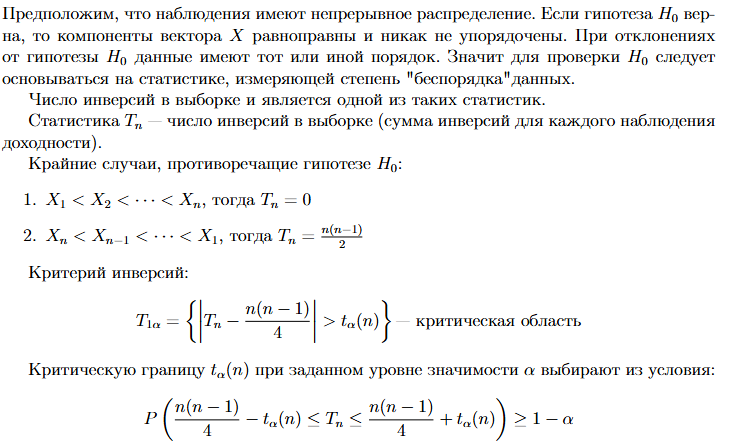

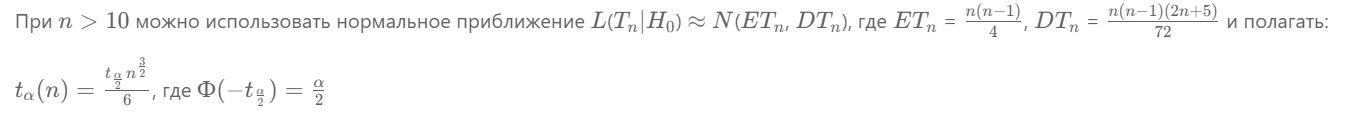

Напишем функцию для подсчета инверсий в последовательности

In [ ]:
def count_inversions(x):
    n = len(x)
    inversions = 0
    for i in range(n - 1):
        for j in range(i + 1, n):
            if x[i] > x[j]:
                inversions += 1
    return inversions

In [ ]:
def inv_test(x, alpha):
    n = len(x)
    T_n = count_inversions(x)
    E_Tn = n * (n - 1) / 4  # Матожидание при H_0
    D_Tn = n * (n - 1) * (2 * n + 5) / 72  # Дисперсия при H_0

    critical_value = norm.ppf(1 - alpha/2, loc = E_Tn, scale = np.sqrt(D_Tn))

    if abs(T_n) > critical_value:
      return False
    else:
      return True


In [ ]:
# #вычисление значения t_a_2

# Phi = lambda x: erf(x/2**0.5)/2
# flag = True
# i = 0.06
# while i < 0.07:
#     if abs(Phi(i) - 0.025) < 0.00000001:
#         print(i)
#         flag = False
#         break
#     i+= 0.00000001
# if flag:
#     print("Not found")

Напишем функцию построения критерия инверсий

In [ ]:
# def inv_test(data, a = 0.05, n = 254, t_a_2 = 0.06270676000031):
#     t_a_n = t_a_2*n**(3/2)/6
#     low_bound = n*(n-1)/4-t_a_n
#     upper_bound = n*(n-1)/4 + t_a_n
#     T = count_inversions(data)
#     if T>=low_bound and T<=upper_bound:
#         return True
#     else:
#         return False

Напишем функцию вычисления мощности критерия инверсий

In [ ]:
def calculate_power_inv(data, alpha, num_of_runs):
    rejections = 0
    for i in range(num_of_runs):
      if inv_test(data[i], alpha) == False:
        rejections += 1
    power = rejections / num_of_runs
    return power

In [ ]:
# def calculate_power_inv(data, alpha, num_of_runs):
#     rejections = 0
#     for i in range(num_of_runs):
#       if inv_test(data[i], alpha, len(data[i]), t_a_2) == False:
#         rejections += 1
#     power = rejections / num_of_runs
#     return power

#Тест на сериях (статья Говарда Левене)

Критерий на основе числа серий и знаков ($k$ и $r$):
- При $H_0$:
$$E(k) = \frac{n-1}{2}, \quad \sigma^2(k) = \frac{n+1}{12}$$.

$$
E(r) = \frac{2n-1}{3}, \quad \sigma^2(r) = \frac{16n-29}{90}.
$$
   - Статистика:
     $$
     Q = \frac{(k - E(k))^2}{\sigma^2(k)} + \frac{(r - E(r))^2}{\sigma^2(r)}
     $$ имеет асимптотически распределение $\chi^2_2$.
   - Критическая область:
     $$
     Q > \chi^2_{2, 1-\alpha},
     $$
     где $\chi^2_{2, 1-\alpha}$ — квантиль распределения хи-квадрат с 2 степенями свободы.

Тест на основе статистики $ Q $ выглядит так:

$$
\varphi(Q) =
\begin{cases}
1, & \text{если } Q > \chi^2_{m, 1-\alpha}, \\
0, & \text{иначе}.
\end{cases}
$$

Напишем функцию для построения теста на сериях

In [ ]:
def runs_test(sequence, alpha):

    n = len(sequence)

    diffs = np.diff(sequence)
    signs = np.sign(diffs)

    runs = 1
    k = 0

    for i in range(1, len(signs)):
        if signs[i] != signs[i-1]:
            runs += 1
        if signs[i] == 1:
            k += 1
    if signs[0] == 1:
        k += 1

    E_k = (n - 1) / 2
    var_k = (n + 1) / 12

    E_r = (2 * n - 1) / 3
    var_r = (16 * n - 29) / 90
    Q = ((k - E_k)**2 / var_k) + ((runs - E_r)**2 / var_r)
    critical_value = chi2.ppf(1 - alpha, 2)

    if Q > critical_value:
      return False
    else:
      return True


Напишем функцию для подсчета мощности теста на сериях

In [ ]:
def calculate_power_runs(data, alpha, num_of_runs):
    rejections = 0
    for i in range(num_of_runs):
      if runs_test(data[i], alpha) == False:
        rejections += 1
    power = rejections / num_of_runs
    return power

# 2. Применение тестов на практике и построение графиков мощности

Генерация данных: будем генерировать различные альтернативы случайности (линейный тренд, периодичность, автокорреляция) по следующим формулам:



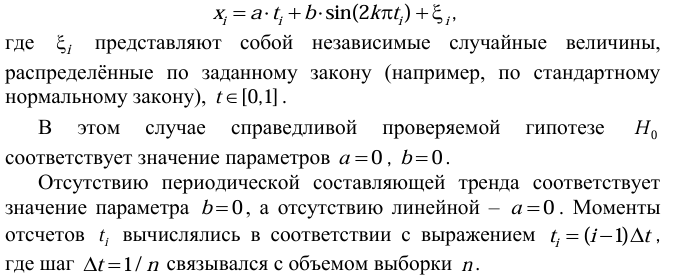

Гипотезы о наличии линейного тренда

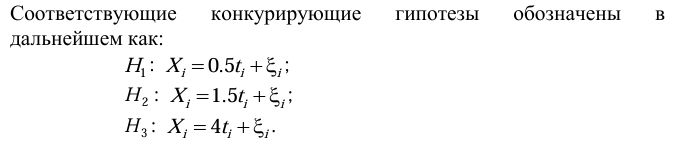

Гипотезы о наличии периодичности

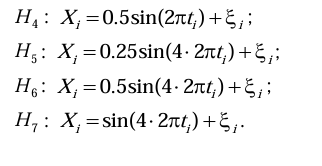

Гипотеза $Н_8$ (автокорреляция в данных)

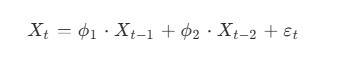

In [ ]:
def generate_sample(n, a, b, k=1):
    """
    Генерирует выборку размера n по формуле:
    x_i = a * t_i + b * sin(2 * k * pi * t_i) + xi_i

    Parameters:
        n (int): Размер выборки
        a (float): Коэффициент линейного тренда
        b (float): Коэффициент периодического тренда
        k (int): Частота синусоидального сигнала

    Returns:
        np.ndarray: Массив значений выборки
    """
    # Шаг времени
    dt = 1 / n
    # Временные моменты t_i
    t = np.arange(0, 1, dt)

    # Случайные величины xi_i ~ N(0, 1)
    xi = np.random.normal(0, 1, n)

    # Вычисление выборки
    x = a * t + b * np.sin(2 * np.pi * k * t) + xi

    return x

Посмотрим на выборки с линейным трендом

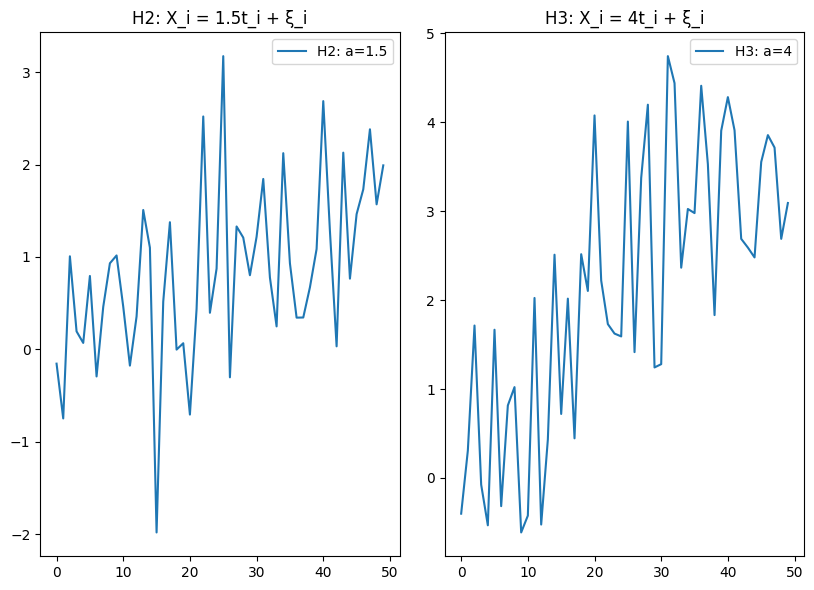

In [ ]:
# Параметры
n = 50  # Размер выборки

# Генерация выборок
#sample_H1 = generate_sample(n, a=0.5, b=0)
sample_H2 = generate_sample(n, a=1.5, b=0)
sample_H3 = generate_sample(n, a=4, b=0)

# Визуализация
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 2)
plt.plot(sample_H2, label="H2: a=1.5")
plt.title("H2: X_i = 1.5t_i + ξ_i")
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(sample_H3, label="H3: a=4")
plt.title("H3: X_i = 4t_i + ξ_i")
plt.legend()

plt.tight_layout()
plt.show()

Посмотрим на выборки с периодичностью

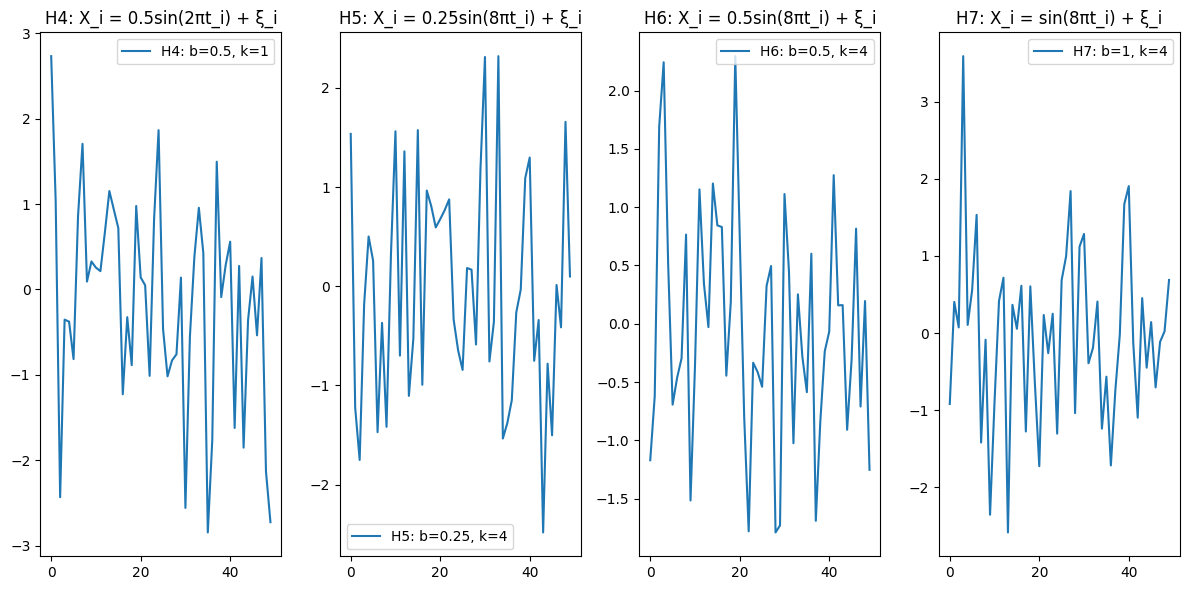

In [ ]:
# Генерация выборок
sample_H4 = generate_sample(n, a=0, b=0.5, k=1)
sample_H5 = generate_sample(n, a=0, b=0.25, k=4)
sample_H6 = generate_sample(n, a=0, b=0.5, k=4)
sample_H7 = generate_sample(n, a=0, b=1, k=4)

# Визуализация
plt.figure(figsize=(12, 6))

plt.subplot(1, 4, 1)
plt.plot(sample_H4, label="H4: b=0.5, k=1")
plt.title("H4: X_i = 0.5sin(2πt_i) + ξ_i")
plt.legend()

plt.subplot(1, 4, 2)
plt.plot(sample_H5, label="H5: b=0.25, k=4")
plt.title("H5: X_i = 0.25sin(8πt_i) + ξ_i")
plt.legend()

plt.subplot(1, 4, 3)
plt.plot(sample_H6, label="H6: b=0.5, k=4")
plt.title("H6: X_i = 0.5sin(8πt_i) + ξ_i")
plt.legend()

plt.subplot(1, 4, 4)
plt.plot(sample_H7, label="H7: b=1, k=4")
plt.title("H7: X_i = sin(8πt_i) + ξ_i")
plt.legend()

plt.tight_layout()
plt.show()

#Мощность тестов при различных альтернативах

In [ ]:
runs = 300

#Альтернативная гипотеза Н1

In [ ]:
data_lt = []
n = [10, 20, 30, 50, 60, 80, 90, 100, 140, 180, 200, 240, 260, 300]
for n_samples in n:
  for num in range (runs):
    size = n_samples
    sample_H1 = generate_sample(size, a=4, b=0)
    data_lt.append(sample_H1)


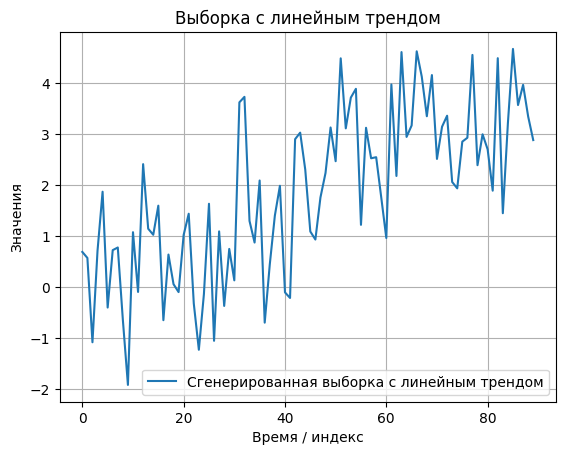

In [ ]:
#Визуализация
plt.plot(np.arange(len(data_lt[2000])), data_lt[2000], label='Сгенерированная выборка с линейным трендом')
plt.xlabel('Время / индекс')
plt.ylabel('Значения')
plt.title('Выборка с линейным трендом')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
ser_corr = {}

In [ ]:
rvn_res = {}

In [ ]:
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
p_sc_lt = []
for alpha in alphas:
  i = 0
  while i < len(data_lt):
    power_sc = calculate_power_sc(data_lt[i:(i + runs)], alpha, runs)
    power = (len(data_lt[i]), alpha, power_sc)
    p_sc_lt.append(power)
    i += runs

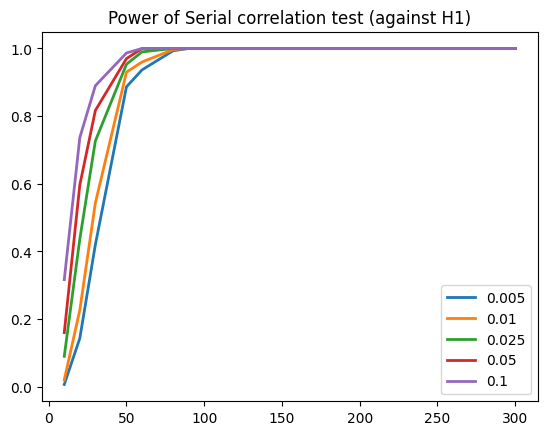

In [ ]:
i = 0
while i < len(p_sc_lt):
  x_i = []
  y_i = []
  for sample in p_sc_lt[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  ser_corr[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of Serial correlation test (against H1)')
plt.show()

In [ ]:
ser_corr

Также посчитаем мощность рангового теста

In [ ]:
p_rvn = []
for alpha in alphas:
  i = 0
  while i < len(data_lt):
    t = len(data_lt[i])
    if t<=100:
      c_alpha = rvn_critical_values[(t, alpha)]
    else:
      c_alpha = 2 + (2/np.sqrt(t))*norm.ppf(alpha) #критическое значение из распределения N(2, 4/T)
    power_rvn = calculate_power_rvn(data_lt[i:(i + runs)], c_alpha, runs)
    power = (t, alpha, power_rvn)
    p_rvn.append(power)
    i += runs

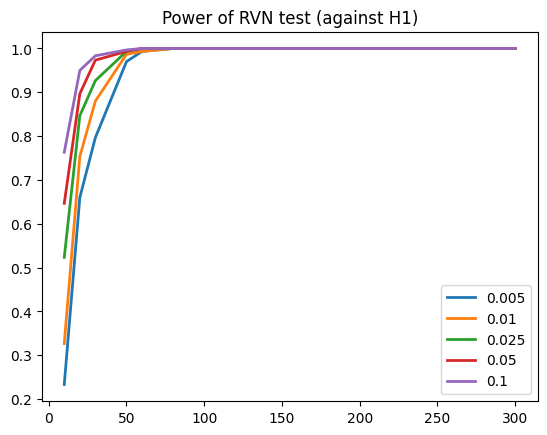

In [ ]:
i = 0
while i < len(p_rvn):
  x_i = []
  y_i = []
  for sample in p_rvn[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  rvn_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of RVN test (against H1)')
plt.show()

In [ ]:
rvn_res

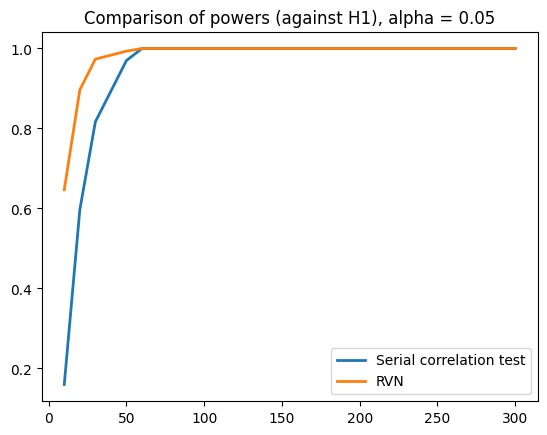

In [ ]:
i = 0
alpha = 0.05
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

plt.legend()
plt.title('Comparison of powers (against H1), alpha = 0.05')
plt.show()

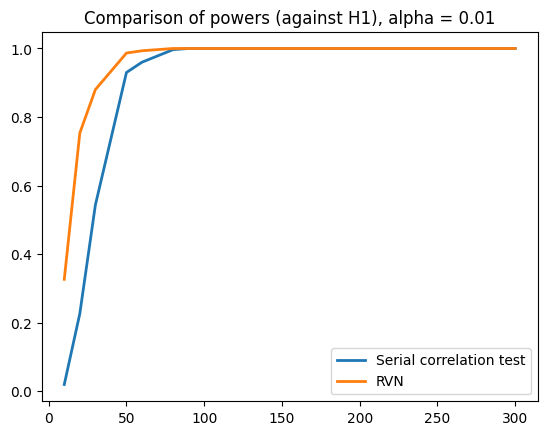

In [ ]:
i = 0
alpha = 0.01
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

plt.legend()
plt.title('Comparison of powers (against H1), alpha = 0.01')
plt.show()

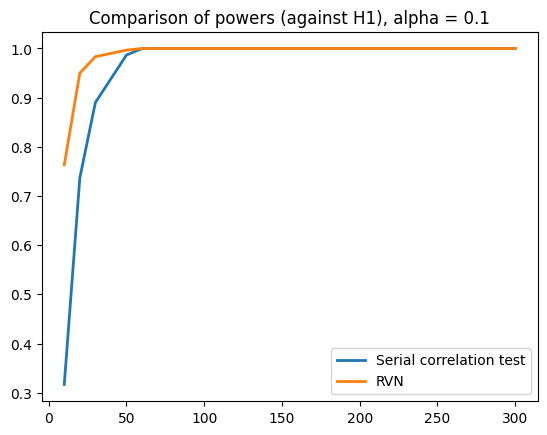

In [ ]:
i = 0
alpha = 0.1
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

plt.legend()
plt.title('Comparison of powers (against H1), alpha = 0.1')
plt.show()

Мощность теста на сериях

In [ ]:
p_runs = []
for alpha in alphas:
  i = 0
  while i < len(data_lt):
    t = len(data_lt[i])
    power_runs = calculate_power_runs(data_lt[i:(i + runs)], alpha, runs)
    power = (t, alpha, power_runs)
    p_runs.append(power)
    i += runs

In [ ]:
print(p_runs)

[(10, 0.005, 0.02666666666666667), (20, 0.005, 0.013333333333333334), (30, 0.005, 0.01), (50, 0.005, 0.0033333333333333335), (60, 0.005, 0.01), (80, 0.005, 0.01), (90, 0.005, 0.006666666666666667), (100, 0.005, 0.006666666666666667), (140, 0.005, 0.0033333333333333335), (180, 0.005, 0.0033333333333333335), (200, 0.005, 0.0033333333333333335), (240, 0.005, 0.0), (260, 0.005, 0.01), (300, 0.005, 0.0033333333333333335), (10, 0.01, 0.07666666666666666), (20, 0.01, 0.023333333333333334), (30, 0.01, 0.03), (50, 0.01, 0.023333333333333334), (60, 0.01, 0.01), (80, 0.01, 0.02), (90, 0.01, 0.01), (100, 0.01, 0.01), (140, 0.01, 0.02666666666666667), (180, 0.01, 0.006666666666666667), (200, 0.01, 0.01), (240, 0.01, 0.0033333333333333335), (260, 0.01, 0.013333333333333334), (300, 0.01, 0.01), (10, 0.025, 0.16), (20, 0.025, 0.05), (30, 0.025, 0.06), (50, 0.025, 0.03333333333333333), (60, 0.025, 0.02), (80, 0.025, 0.04), (90, 0.025, 0.03), (100, 0.025, 0.02), (140, 0.025, 0.03333333333333333), (180, 

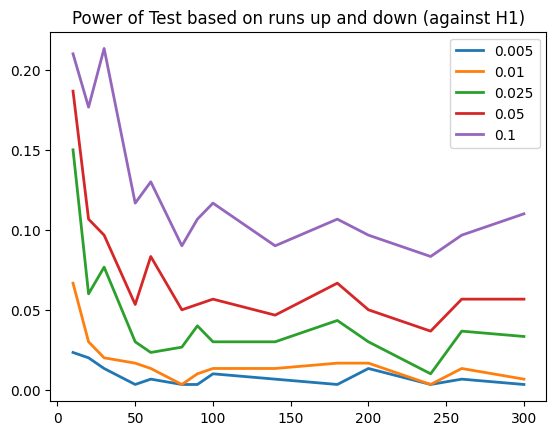

In [ ]:
i = 0
while i < len(p_runs):
  x_i = []
  y_i = []
  for sample in p_runs[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of Test based on runs up and down (against H1)')
plt.show()

Также посчитаем мощность критерия инверсий

In [ ]:
t_a_2 = 0.06270676000031
p_inv_lt = []

for alpha in alphas:
  i = 0
  while i < len(data_lt):
    power_inv = calculate_power_inv(data_lt[i:(i + runs)], alpha, runs)
    power = (len(data_lt[i]), alpha, power_inv)
    p_inv_lt.append(power)
    i += runs

print(p_inv_lt)

[(10, 0.005, 0.0), (20, 0.005, 0.0), (30, 0.005, 0.0), (50, 0.005, 0.0), (60, 0.005, 0.0), (80, 0.005, 0.0), (90, 0.005, 0.0), (100, 0.005, 0.0), (140, 0.005, 0.0), (180, 0.005, 0.0), (200, 0.005, 0.0), (240, 0.005, 0.0), (260, 0.005, 0.0), (300, 0.005, 0.0), (10, 0.01, 0.0), (20, 0.01, 0.0), (30, 0.01, 0.0), (50, 0.01, 0.0), (60, 0.01, 0.0), (80, 0.01, 0.0), (90, 0.01, 0.0), (100, 0.01, 0.0), (140, 0.01, 0.0), (180, 0.01, 0.0), (200, 0.01, 0.0), (240, 0.01, 0.0), (260, 0.01, 0.0), (300, 0.01, 0.0), (10, 0.025, 0.0), (20, 0.025, 0.0), (30, 0.025, 0.0), (50, 0.025, 0.0), (60, 0.025, 0.0), (80, 0.025, 0.0), (90, 0.025, 0.0), (100, 0.025, 0.0), (140, 0.025, 0.0), (180, 0.025, 0.0), (200, 0.025, 0.0), (240, 0.025, 0.0), (260, 0.025, 0.0), (300, 0.025, 0.0), (10, 0.05, 0.0), (20, 0.05, 0.0), (30, 0.05, 0.0), (50, 0.05, 0.0), (60, 0.05, 0.0), (80, 0.05, 0.0), (90, 0.05, 0.0), (100, 0.05, 0.0), (140, 0.05, 0.0), (180, 0.05, 0.0), (200, 0.05, 0.0), (240, 0.05, 0.0), (260, 0.05, 0.0), (300, 0.0

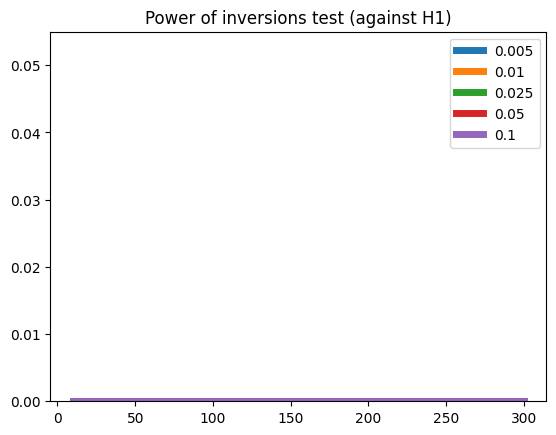

In [ ]:
i = 0
while i < len(p_inv_lt):
  x_i = []
  y_i = []
  for sample in p_inv_lt[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  plt.plot(x_i, y_i, linewidth=5, label = str(alpha))
  i += len(n)

plt.ylim(bottom=0)
plt.legend()
plt.title('Power of inversions test (against H1)')
plt.show()

Теперь в качестве альтернативы возьмем периодичность (гипотезы Н4-Н7)

#Альтернативная гипотеза Н2

In [ ]:
n = [10, 20, 30, 50, 60, 80, 90, 100, 140, 180, 200, 240, 260, 300]
data_pt = []
for n_samples in n:
  for num in range (runs):
    size = n_samples
    sample_H2 = generate_sample(size, a=0, b=0.5, k=1)
    data_pt.append(sample_H2)

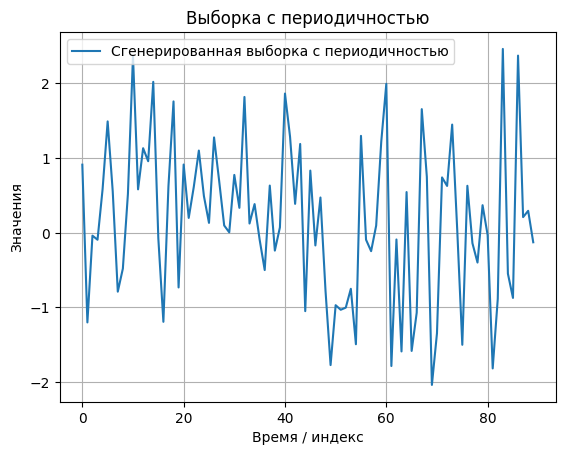

In [ ]:
#Визуализация
plt.plot(np.arange(len(data_pt[2000])), data_pt[2000], label='Сгенерированная выборка с периодичностью')
plt.xlabel('Время / индекс')
plt.ylabel('Значения')
plt.title('Выборка с периодичностью')
plt.legend()
plt.grid(True)
plt.show()

Мощность теста сериальной корреляции

In [ ]:
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
p_sc_p = []
for alpha in alphas:
  i = 0
  while i < len(data_pt):
    power_sc = calculate_power_sc(data_pt[i:(i + runs)], alpha, runs)
    power = (len(data_pt[i]), alpha, power_sc)
    p_sc_p.append(power)
    i += runs

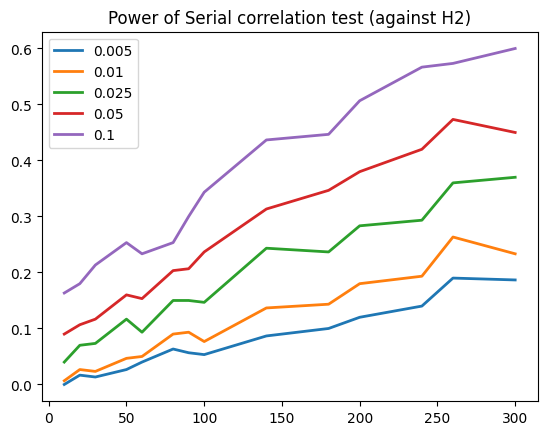

In [ ]:
i = 0
ser_corr = {}
while i < len(p_sc_p):
  x_i = []
  y_i = []
  for sample in p_sc_p[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  ser_corr[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of Serial correlation test (against H2)')
plt.show()

Мощность рангового теста

In [ ]:
p_rvn_pt = []
for alpha in alphas:
  i = 0
  while i < len(data_pt):
    t = len(data_pt[i])
    if t<=100:
      c_alpha = rvn_critical_values[(t, alpha)]
    else:
      c_alpha = 2 + (2/np.sqrt(t))*norm.ppf(alpha) #критическое значение из распределения N(2, 4/T)
    power_rvn = calculate_power_rvn(data_pt[i:(i + runs)], c_alpha, runs)
    power = (t, alpha, power_rvn)
    p_rvn_pt.append(power)
    i += runs

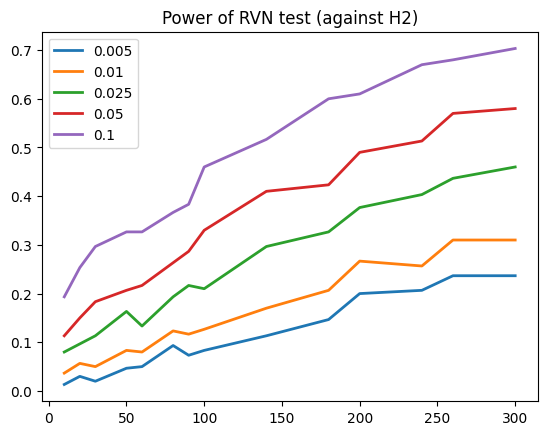

In [ ]:
i = 0
rvn_res = {}
while i < len(p_rvn_pt):
  x_i = []
  y_i = []
  for sample in p_rvn_pt[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  rvn_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of RVN test (against H2)')
plt.show()

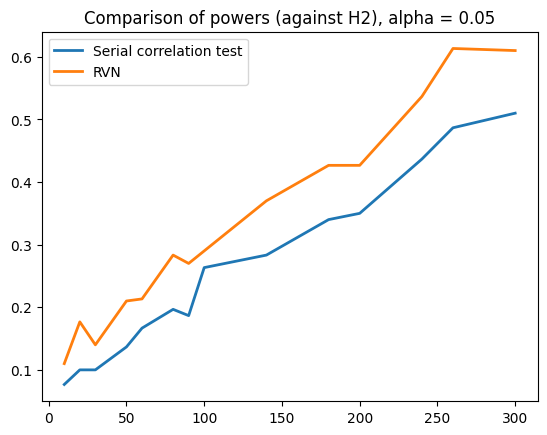

In [ ]:
i = 0
alpha = 0.05
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

plt.legend()
plt.title('Comparison of powers (against H2), alpha = 0.05')
plt.show()

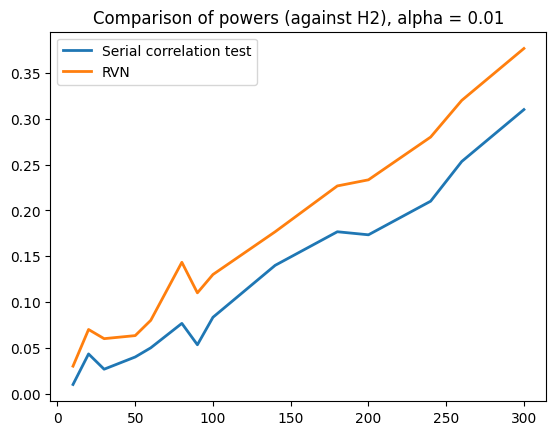

In [ ]:
i = 0
alpha = 0.01
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

plt.legend()
plt.title('Comparison of powers (against H2), alpha = 0.01')
plt.show()

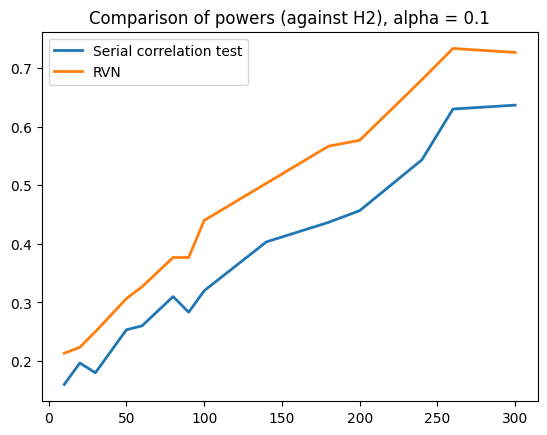

In [ ]:
i = 0
alpha = 0.1
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

plt.legend()
plt.title('Comparison of powers (against H2), alpha = 0.1')
plt.show()

Мощность теста на сериях

In [ ]:
p_runs = []
for alpha in alphas:
  i = 0
  while i < len(data_pt):
    t = len(data_pt[i])
    power_runs = calculate_power_runs(data_pt[i:(i + runs)], alpha, runs)
    power = (t, alpha, power_runs)
    p_runs.append(power)
    i += runs

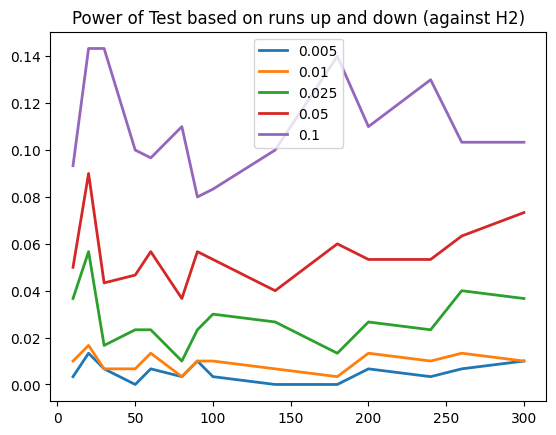

In [ ]:
i = 0
while i < len(p_runs):
  x_i = []
  y_i = []
  for sample in p_runs[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of Test based on runs up and down (against H2)')
plt.show()

Мощность критерия инверсий

In [ ]:
t_a_2 = 0.06270676000031
p_inv_pt = []
for alpha in alphas:
  i = 0
  while i < len(data_pt):
    power_inv = calculate_power_inv(data_pt[i:(i + runs)], alpha, runs)
    power = (len(data_pt[i]), alpha, power_inv)
    p_inv_pt.append(power)
    i += runs

print(p_inv_pt)

[(10, 0.005, 0.006666666666666667), (20, 0.005, 0.023333333333333334), (30, 0.005, 0.06333333333333334), (50, 0.005, 0.11), (60, 0.005, 0.17), (80, 0.005, 0.31333333333333335), (90, 0.005, 0.33666666666666667), (100, 0.005, 0.3333333333333333), (140, 0.005, 0.6466666666666666), (180, 0.005, 0.7733333333333333), (200, 0.005, 0.78), (240, 0.005, 0.9366666666666666), (260, 0.005, 0.92), (300, 0.005, 0.9566666666666667), (10, 0.01, 0.023333333333333334), (20, 0.01, 0.05333333333333334), (30, 0.01, 0.11), (50, 0.01, 0.15), (60, 0.01, 0.25666666666666665), (80, 0.01, 0.43666666666666665), (90, 0.01, 0.42333333333333334), (100, 0.01, 0.42), (140, 0.01, 0.7266666666666667), (180, 0.01, 0.8466666666666667), (200, 0.01, 0.8666666666666667), (240, 0.01, 0.9533333333333334), (260, 0.01, 0.9466666666666667), (300, 0.01, 0.9633333333333334), (10, 0.025, 0.043333333333333335), (20, 0.025, 0.11), (30, 0.025, 0.19333333333333333), (50, 0.025, 0.26), (60, 0.025, 0.41), (80, 0.025, 0.57), (90, 0.025, 0.6

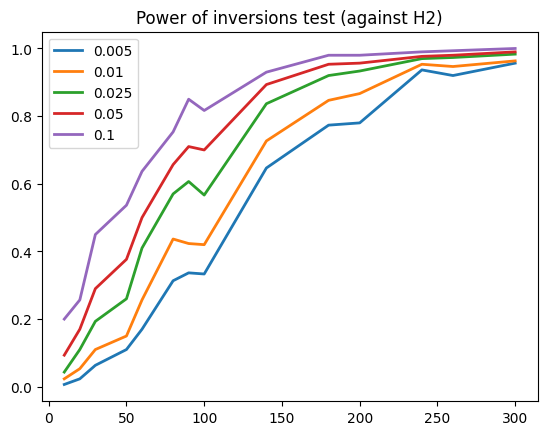

In [ ]:
i = 0
inv_res = {}
while i < len(p_inv_pt):
  x_i = []
  y_i = []
  for sample in p_inv_pt[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  inv_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of inversions test (against H2)')
plt.show()

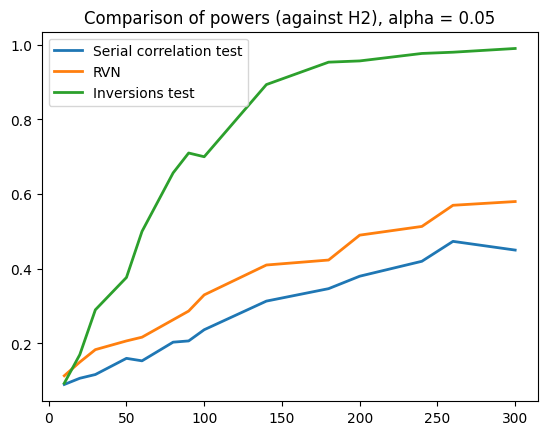

In [ ]:
i = 0
alpha = 0.05
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = inv_res[alpha][0]
Y3 = inv_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Inversions test')

plt.legend()
plt.title('Comparison of powers (against H2), alpha = 0.05')
plt.show()

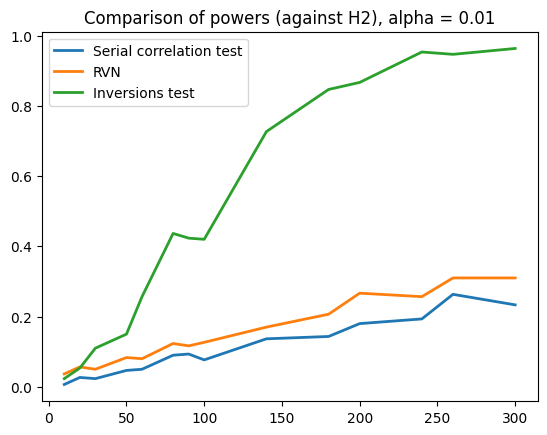

In [ ]:
i = 0
alpha = 0.01
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = inv_res[alpha][0]
Y3 = inv_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Inversions test')

plt.legend()
plt.title('Comparison of powers (against H2), alpha = 0.01')
plt.show()

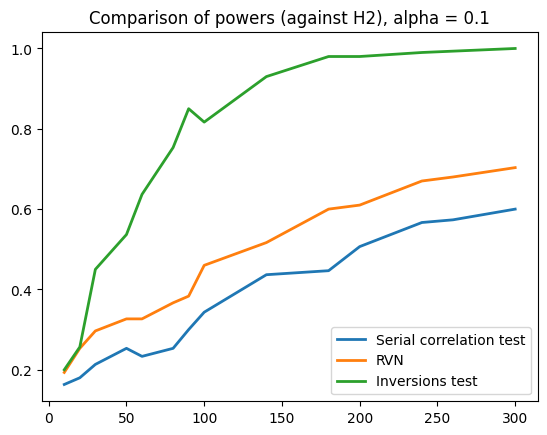

In [ ]:
i = 0
alpha = 0.1
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = inv_res[alpha][0]
Y3 = inv_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Inversions test')

plt.legend()
plt.title('Comparison of powers (against H2), alpha = 0.1')
plt.show()

# Альтернативная гипотеза Н3

In [ ]:
n = [10, 20, 30, 50, 60, 80, 90, 100, 140, 180, 200, 240, 260, 300]
data_pt = []
for n_samples in n:
  for num in range (runs):
    size = n_samples
    sample_H3 = generate_sample(size, a=0, b=1, k=4)
    data_pt.append(sample_H3)

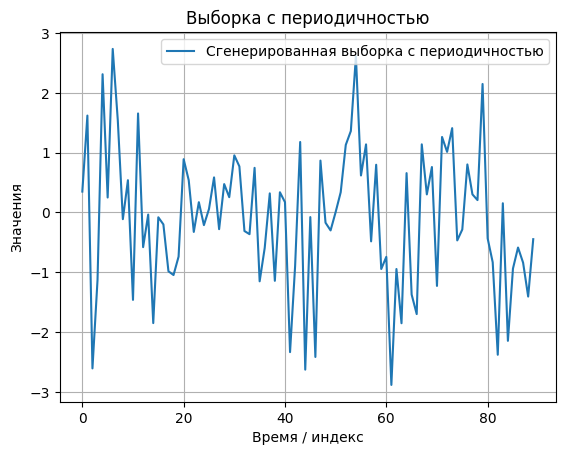

In [ ]:
#Визуализация
plt.plot(np.arange(len(data_pt[2000])), data_pt[2000], label='Сгенерированная выборка с периодичностью')
plt.xlabel('Время / индекс')
plt.ylabel('Значения')
plt.title('Выборка с периодичностью')
plt.legend()
plt.grid(True)
plt.show()

Мощность теста сериальной корреляции

In [ ]:
p_sc_p = []
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
for alpha in alphas:
  i = 0
  while i < len(data_pt):
    power_sc = calculate_power_sc(data_pt[i:(i + runs)], alpha, runs)
    power = (len(data_pt[i]), alpha, power_sc)
    p_sc_p.append(power)
    i += runs

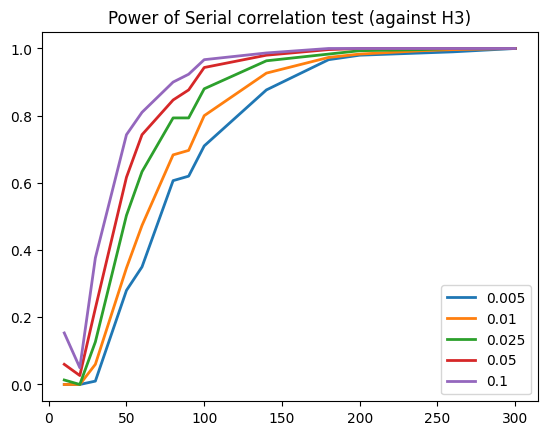

In [ ]:
i = 0
ser_corr = {}
while i < len(p_sc_p):
  x_i = []
  y_i = []
  for sample in p_sc_p[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  ser_corr[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of Serial correlation test (against H3)')
plt.show()

Мощность рангового теста

In [ ]:
p_rvn_pt = []
for alpha in alphas:
  i = 0
  while i < len(data_pt):
    t = len(data_pt[i])
    if t <= 100:
      c_alpha = rvn_critical_values[(t, alpha)]
    else:
      c_alpha = 2 + (2/np.sqrt(t))*norm.ppf(alpha) #критическое значение из распределения N(2, 4/T)
    power_rvn = calculate_power_rvn(data_pt[i:(i + runs)], c_alpha, runs)
    power = (t, alpha, power_rvn)
    p_rvn_pt.append(power)
    i += runs

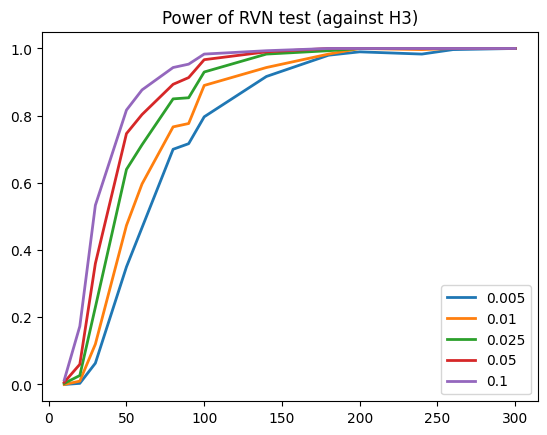

In [ ]:
i = 0
rvn_res = {}
while i < len(p_rvn_pt):
  x_i = []
  y_i = []
  for sample in p_rvn_pt[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  rvn_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of RVN test (against H3)')
plt.show()

Мощность теста на сериях

In [ ]:
p_runs = []
for alpha in alphas:
  i = 0
  while i < len(data_pt):
    t = len(data_pt[i])
    power_runs = calculate_power_runs(data_pt[i:(i + runs)], alpha, runs)
    power = (t, alpha, power_runs)
    p_runs.append(power)
    i += runs

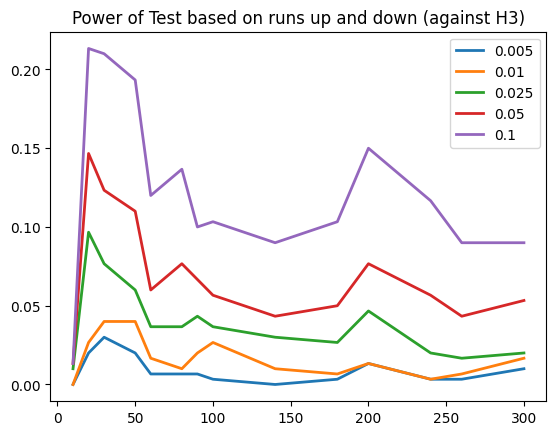

In [ ]:
i = 0
while i < len(p_runs):
  x_i = []
  y_i = []
  for sample in p_runs[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of Test based on runs up and down (against H3)')
plt.show()

Мощность критерия инверсий

In [ ]:
t_a_2 = 0.06270676000031
p_inv_pt = []

for alpha in alphas:
  i = 0
  while i < len(data_pt):
    power_inv = calculate_power_inv(data_pt[i:(i + runs)], alpha, runs)
    power = (len(data_pt[i]), alpha, power_inv)
    p_inv_pt.append(power)
    i += runs

print(p_inv_pt)

[(10, 0.005, 0.0), (20, 0.005, 0.0), (30, 0.005, 0.0033333333333333335), (50, 0.005, 0.006666666666666667), (60, 0.005, 0.0033333333333333335), (80, 0.005, 0.01), (90, 0.005, 0.016666666666666666), (100, 0.005, 0.02666666666666667), (140, 0.005, 0.023333333333333334), (180, 0.005, 0.07), (200, 0.005, 0.10666666666666667), (240, 0.005, 0.08666666666666667), (260, 0.005, 0.12), (300, 0.005, 0.16666666666666666), (10, 0.01, 0.0), (20, 0.01, 0.0033333333333333335), (30, 0.01, 0.0033333333333333335), (50, 0.01, 0.01), (60, 0.01, 0.006666666666666667), (80, 0.01, 0.02666666666666667), (90, 0.01, 0.03666666666666667), (100, 0.01, 0.04), (140, 0.01, 0.056666666666666664), (180, 0.01, 0.1), (200, 0.01, 0.15), (240, 0.01, 0.16333333333333333), (260, 0.01, 0.18666666666666668), (300, 0.01, 0.24), (10, 0.025, 0.0), (20, 0.025, 0.016666666666666666), (30, 0.025, 0.01), (50, 0.025, 0.02), (60, 0.025, 0.03333333333333333), (80, 0.025, 0.05333333333333334), (90, 0.025, 0.08666666666666667), (100, 0.02

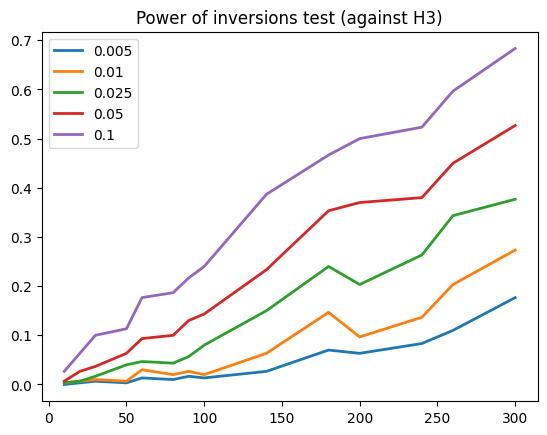

In [ ]:
i = 0
inv_res = {}
while i < len(p_inv_pt):
  x_i = []
  y_i = []
  for sample in p_inv_pt[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  inv_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of inversions test (against H3)')
plt.show()

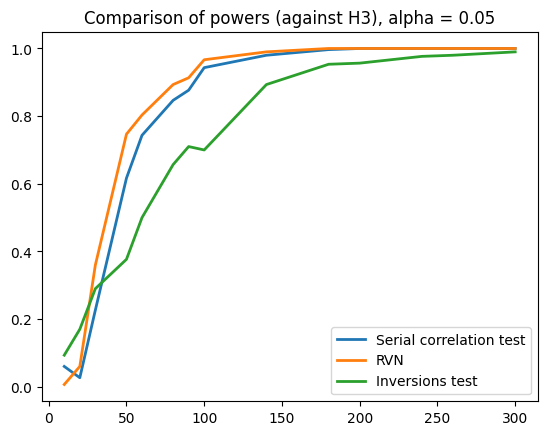

In [ ]:
i = 0
alpha = 0.05
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = inv_res[alpha][0]
Y3 = inv_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Inversions test')

plt.legend()
plt.title('Comparison of powers (against H3), alpha = 0.05')
plt.show()

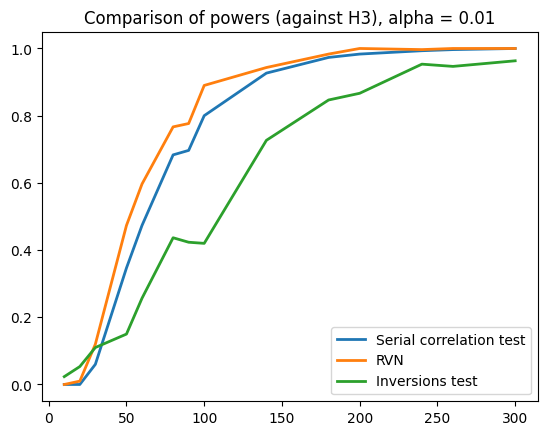

In [ ]:
i = 0
alpha = 0.01
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = inv_res[alpha][0]
Y3 = inv_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Inversions test')

plt.legend()
plt.title('Comparison of powers (against H3), alpha = 0.01')
plt.show()

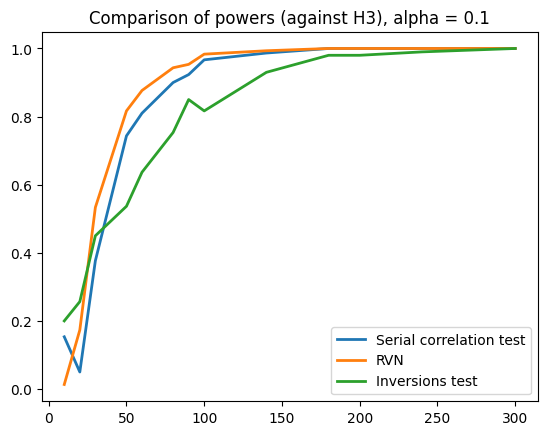

In [ ]:
i = 0
alpha = 0.1
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = inv_res[alpha][0]
Y3 = inv_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Inversions test')

plt.legend()
plt.title('Comparison of powers (against H3), alpha = 0.1')
plt.show()

# Альтернативная гипотеза H4

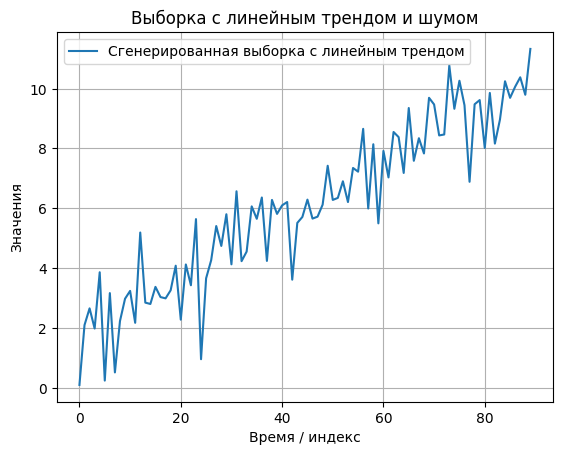

In [ ]:
data_lt = []
n = [10, 20, 30, 50, 60, 80, 90, 100, 140, 180, 200, 240, 260, 300]
for n_samples in n:
  for num in range (runs):
    size = n_samples
    # Генерация данных с линейным трендом
    noise = np.random.normal(0, 1, size)
    trend = np.arange(size)
    data = noise + trend*0.1
    min_value = np.min(data)
    if min_value <= 0:
      data = data - min_value + 0.1
    data_lt.append(data)

# Визуализация
plt.plot(np.arange(len(data_lt[2000])), data_lt[2000], label='Сгенерированная выборка с линейным трендом')
plt.xlabel('Время / индекс')
plt.ylabel('Значения')
plt.title('Выборка с линейным трендом и шумом')
plt.legend()
plt.grid(True)
plt.show()

Мощность теста сериальной корреляции

In [ ]:
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
p_sc_lt = []
for alpha in alphas:
  i = 0
  while i < len(data_lt):
    power_sc = calculate_power_sc(data_lt[i:(i + runs)], alpha, runs)
    power = (len(data_lt[i]), alpha, power_sc)
    p_sc_lt.append(power)
    i += runs

In [ ]:
print(p_sc_lt)

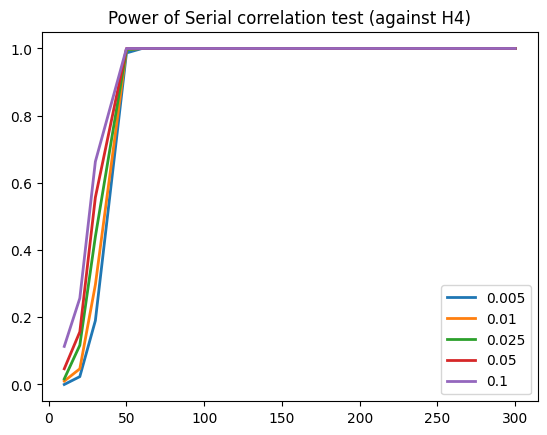

In [ ]:
i = 0
ser_corr = {}
while i < len(p_sc_lt):
  x_i = []
  y_i = []
  for sample in p_sc_lt[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  ser_corr[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of Serial correlation test (against H4)')
plt.show()

Также посчитаем мощность рангового теста

In [ ]:
p_rvn = []
for alpha in alphas:
  i = 0
  while i < len(data_lt):
    t = len(data_lt[i])
    if t<=100:
      c_alpha = rvn_critical_values[(t, alpha)]
    else:
      c_alpha = 2 + (2/np.sqrt(t))*norm.ppf(alpha) #критическое значение из распределения N(2, 4/T)
    power_rvn = calculate_power_rvn(data_lt[i:(i + runs)], c_alpha, runs)
    power = (t, alpha, power_rvn)
    p_rvn.append(power)
    i += runs

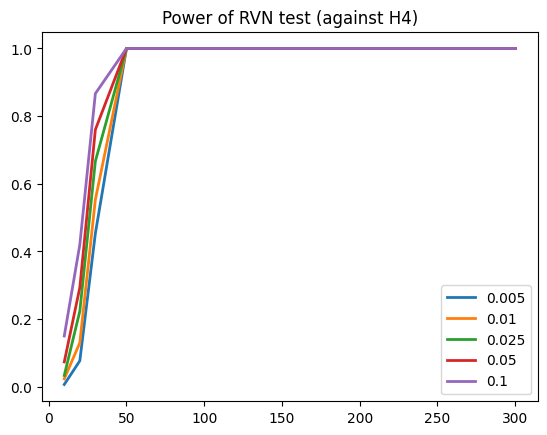

In [ ]:
i = 0
rvn_res = {}
while i < len(p_rvn):
  x_i = []
  y_i = []
  for sample in p_rvn[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  rvn_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of RVN test (against H4)')
plt.show()

Мощность теста на сериях

In [ ]:
p_runs = []
for alpha in alphas:
  i = 0
  while i < len(data_lt):
    t = len(data_lt[i])
    power_runs = calculate_power_runs(data_lt[i:(i + runs)], alpha, runs)
    power = (t, alpha, power_runs)
    p_runs.append(power)
    i += runs

In [ ]:
print(p_runs)

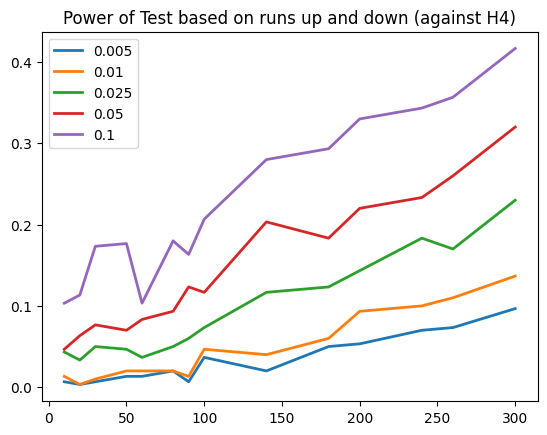

In [ ]:
i = 0
runs_res = {}
while i < len(p_runs):
  x_i = []
  y_i = []
  for sample in p_runs[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  runs_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of Test based on runs up and down (against H4)')
plt.show()

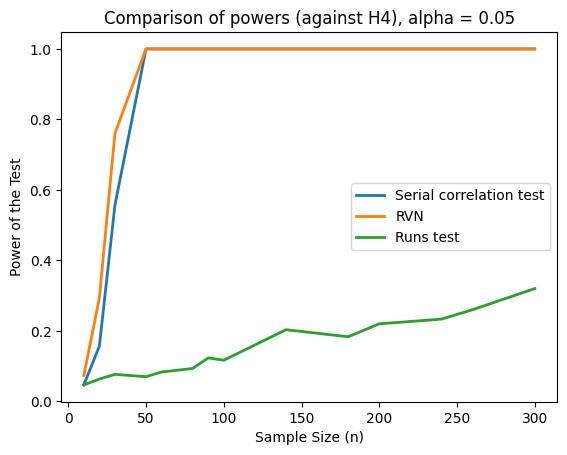

In [ ]:
i = 0
alpha = 0.05
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = runs_res[alpha][0]
Y3 = runs_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Runs test')
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')
plt.legend()
plt.title('Comparison of powers (against H4), alpha = 0.05')
plt.show()

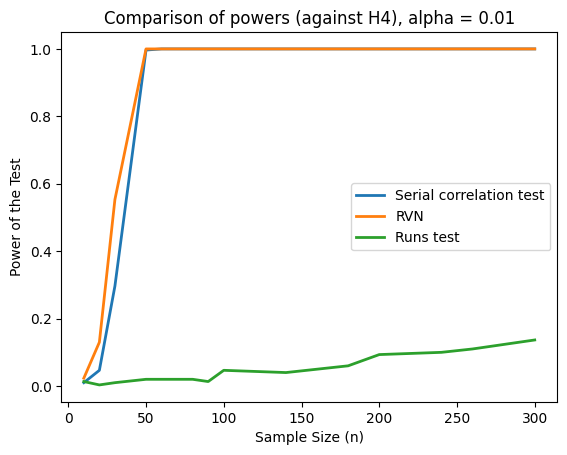

In [ ]:
i = 0
alpha = 0.01
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = runs_res[alpha][0]
Y3 = runs_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Runs test')
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')

plt.legend()
plt.title('Comparison of powers (against H4), alpha = 0.01')
plt.show()

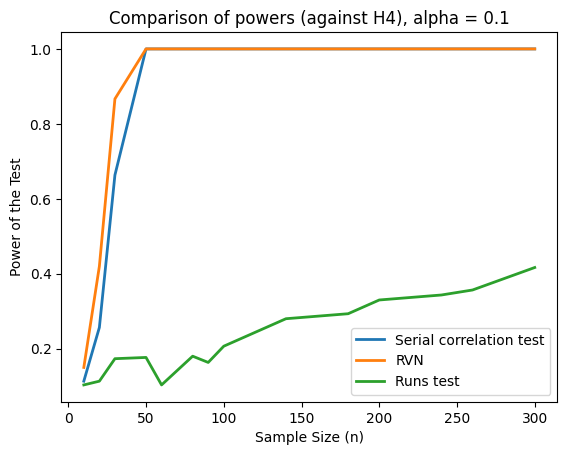

In [ ]:
i = 0
alpha = 0.1
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = runs_res[alpha][0]
Y3 = runs_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Runs test')
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')

plt.legend()
plt.title('Comparison of powers (against H4), alpha = 0.1')
plt.show()

Также посчитаем мощность критерия инверсий

In [ ]:
t_a_2 = 0.06270676000031
p_inv_lt = []

for alpha in alphas:
  i = 0
  while i < len(data_lt):
    power_inv = calculate_power_inv(data_lt[i:(i + runs)], alpha, runs)
    power = (len(data_lt[i]), alpha, power_inv)
    p_inv_lt.append(power)
    i += runs

print(p_inv_lt)

[(10, 0.005, 0.0), (20, 0.005, 0.0), (30, 0.005, 0.0), (50, 0.005, 0.0), (60, 0.005, 0.0), (80, 0.005, 0.0), (90, 0.005, 0.0), (100, 0.005, 0.0), (140, 0.005, 0.0), (180, 0.005, 0.0), (200, 0.005, 0.0), (240, 0.005, 0.0), (260, 0.005, 0.0), (300, 0.005, 0.0), (10, 0.01, 0.0), (20, 0.01, 0.0), (30, 0.01, 0.0), (50, 0.01, 0.0), (60, 0.01, 0.0), (80, 0.01, 0.0), (90, 0.01, 0.0), (100, 0.01, 0.0), (140, 0.01, 0.0), (180, 0.01, 0.0), (200, 0.01, 0.0), (240, 0.01, 0.0), (260, 0.01, 0.0), (300, 0.01, 0.0), (10, 0.025, 0.0), (20, 0.025, 0.0), (30, 0.025, 0.0), (50, 0.025, 0.0), (60, 0.025, 0.0), (80, 0.025, 0.0), (90, 0.025, 0.0), (100, 0.025, 0.0), (140, 0.025, 0.0), (180, 0.025, 0.0), (200, 0.025, 0.0), (240, 0.025, 0.0), (260, 0.025, 0.0), (300, 0.025, 0.0), (10, 0.05, 0.0), (20, 0.05, 0.0), (30, 0.05, 0.0), (50, 0.05, 0.0), (60, 0.05, 0.0), (80, 0.05, 0.0), (90, 0.05, 0.0), (100, 0.05, 0.0), (140, 0.05, 0.0), (180, 0.05, 0.0), (200, 0.05, 0.0), (240, 0.05, 0.0), (260, 0.05, 0.0), (300, 0.0

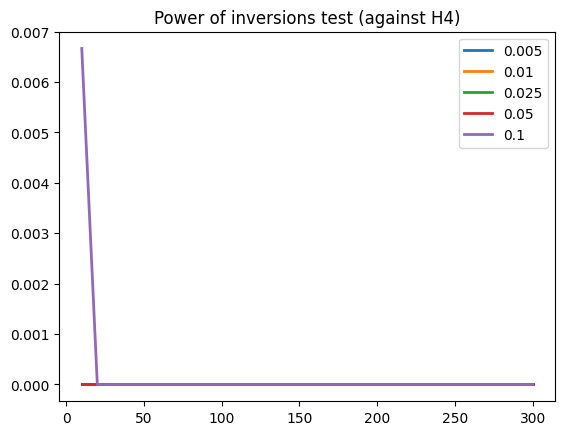

In [ ]:
i = 0
while i < len(p_inv_lt):
  x_i = []
  y_i = []
  for sample in p_inv_lt[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of inversions test (against H4)')
plt.show()

# Альтернативная гипотеза H6

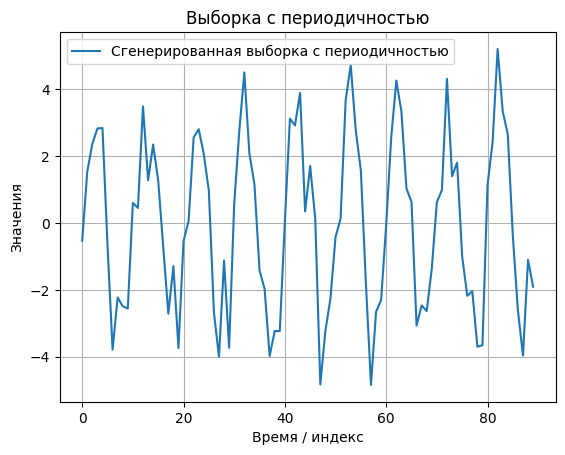

In [ ]:
n = [10, 20, 30, 50, 60, 80, 90, 100, 140, 180, 200, 240, 260, 300]
data_pt = []
for n_samples in n:
  for num in range (runs):
    size = n_samples
    time = np.arange(n_samples)
    periodic = 3 * np.sin(2 * np.pi * 0.1 * time)
    noise = np.random.normal(0, 1, n_samples)
    data = periodic + noise
    data_pt.append(data)

# Визуализация
plt.plot(np.arange(len(data_pt[2000])), data_pt[2000], label='Сгенерированная выборка с периодичностью')
plt.xlabel('Время / индекс')
plt.ylabel('Значения')
plt.title('Выборка с периодичностью')
plt.legend()
plt.grid(True)
plt.show()

Мощность теста сериальной корреляции

In [ ]:
p_sc_p = []
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
for alpha in alphas:
  i = 0
  while i < len(data_pt):
    power_sc = calculate_power_sc(data_pt[i:(i + runs)], alpha, runs)
    power = (len(data_pt[i]), alpha, power_sc)
    p_sc_p.append(power)
    i += runs

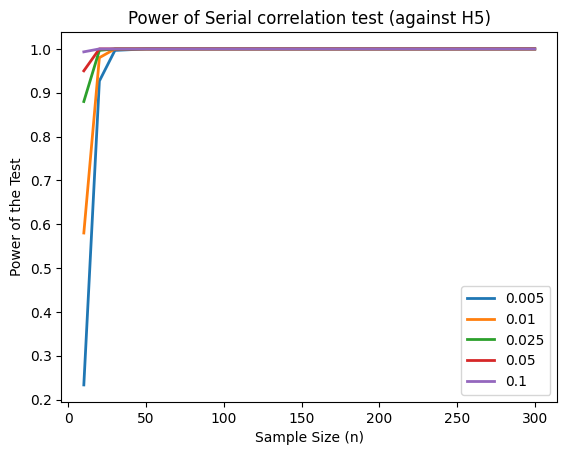

In [ ]:
i = 0
ser_corr = {}
while i < len(p_sc_p):
  x_i = []
  y_i = []
  for sample in p_sc_p[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  ser_corr[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')
plt.title('Power of Serial correlation test (against H5)')
plt.show()

Мощность рангового теста

In [ ]:
p_rvn_pt = []
for alpha in alphas:
  i = 0
  while i < len(data_pt):
    t = len(data_pt[i])
    if t<=100:
      c_alpha = rvn_critical_values[(t, alpha)]
    else:
      c_alpha = 2 + (2/np.sqrt(t))*norm.ppf(alpha) #критическое значение из распределения N(2, 4/T)
    power_rvn = calculate_power_rvn(data_pt[i:(i + runs)], c_alpha, runs)
    power = (t, alpha, power_rvn)
    p_rvn_pt.append(power)
    i += runs

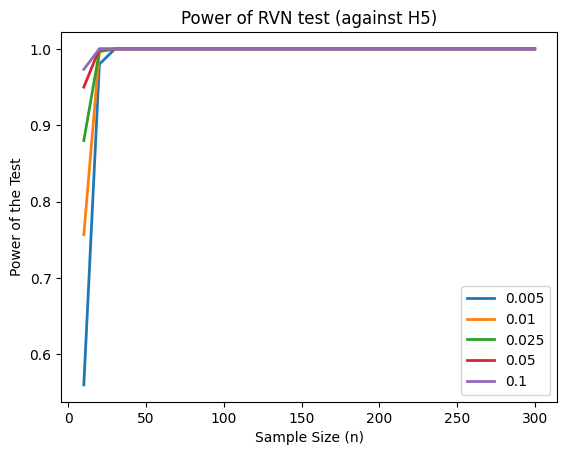

In [ ]:
i = 0
rvn_res = {}
while i < len(p_rvn_pt):
  x_i = []
  y_i = []
  for sample in p_rvn_pt[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  rvn_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')
plt.title('Power of RVN test (against H5)')
plt.show()

Мощность теста на сериях

In [ ]:
p_runs = []
for alpha in alphas:
  i = 0
  while i < len(data_pt):
    t = len(data_pt[i])
    power_runs = calculate_power_runs(data_pt[i:(i + runs)], alpha, runs)
    power = (t, alpha, power_runs)
    p_runs.append(power)
    i += runs

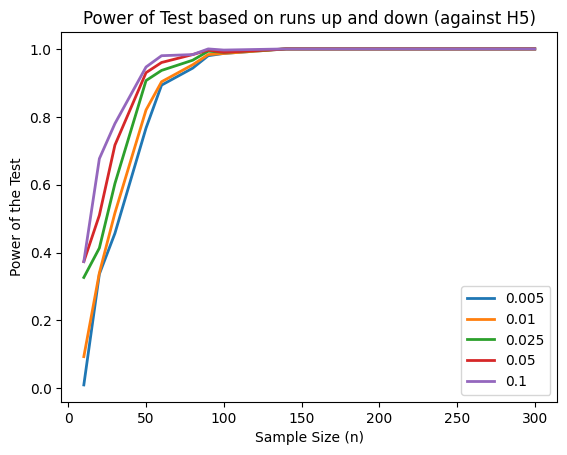

In [ ]:
i = 0
runs_res = {}
while i < len(p_runs):
  x_i = []
  y_i = []
  for sample in p_runs[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  runs_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')
plt.title('Power of Test based on runs up and down (against H5)')
plt.show()

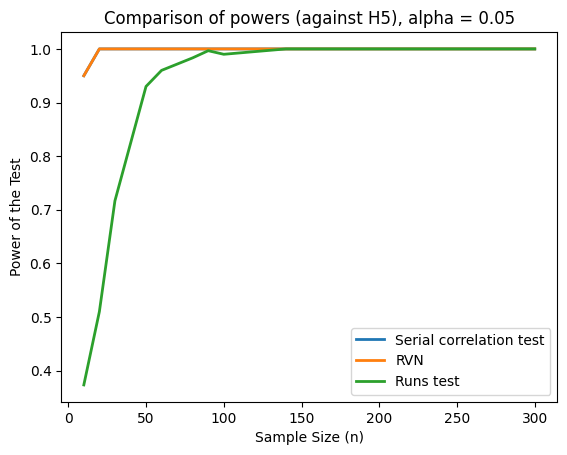

In [ ]:
i = 0
alpha = 0.05
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = runs_res[alpha][0]
Y3 = runs_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Runs test')
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')
plt.legend()
plt.title('Comparison of powers (against H5), alpha = 0.05')
plt.show()

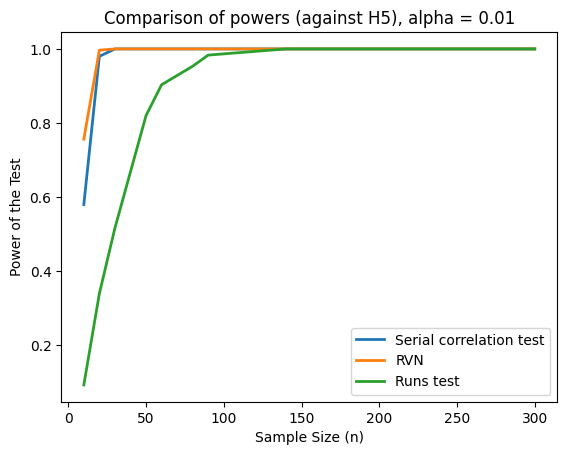

In [ ]:
i = 0
alpha = 0.01
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = runs_res[alpha][0]
Y3 = runs_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Runs test')
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')

plt.legend()
plt.title('Comparison of powers (against H5), alpha = 0.01')
plt.show()

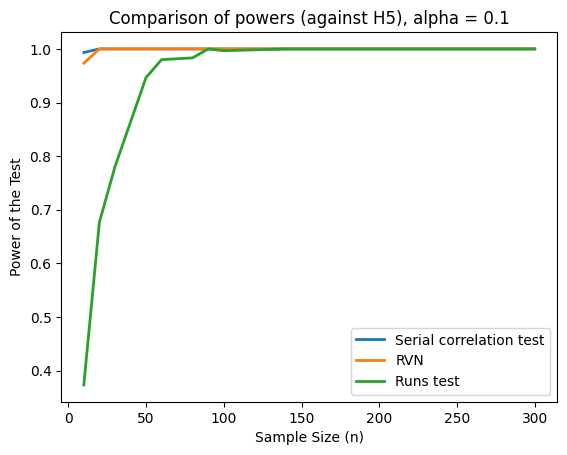

In [ ]:
i = 0
alpha = 0.1
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = runs_res[alpha][0]
Y3 = runs_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Runs test')
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')

plt.legend()
plt.title('Comparison of powers (against H5), alpha = 0.1')
plt.show()

Мощность критерия инверсий

In [ ]:
t_a_2 = 0.06270676000031
p_inv_pt = []

for alpha in alphas:
  i = 0
  while i < len(data_pt):
    power_inv = calculate_power_inv(data_pt[i:(i + runs)], alpha, runs)
    power = (len(data_pt[i]), alpha, power_inv)
    p_inv_pt.append(power)
    i += runs

print(p_inv_pt)

[(10, 0.005, 0.016666666666666666), (20, 0.005, 0.0), (30, 0.005, 0.0), (50, 0.005, 0.0), (60, 0.005, 0.0), (80, 0.005, 0.0), (90, 0.005, 0.0), (100, 0.005, 0.0), (140, 0.005, 0.0), (180, 0.005, 0.0), (200, 0.005, 0.0), (240, 0.005, 0.0), (260, 0.005, 0.0), (300, 0.005, 0.0), (10, 0.01, 0.16), (20, 0.01, 0.0033333333333333335), (30, 0.01, 0.0033333333333333335), (50, 0.01, 0.0), (60, 0.01, 0.0), (80, 0.01, 0.0), (90, 0.01, 0.0), (100, 0.01, 0.0), (140, 0.01, 0.0), (180, 0.01, 0.0), (200, 0.01, 0.0), (240, 0.01, 0.0), (260, 0.01, 0.0), (300, 0.01, 0.0), (10, 0.025, 0.25), (20, 0.025, 0.03), (30, 0.025, 0.016666666666666666), (50, 0.025, 0.0), (60, 0.025, 0.0), (80, 0.025, 0.0), (90, 0.025, 0.0), (100, 0.025, 0.0), (140, 0.025, 0.0), (180, 0.025, 0.0), (200, 0.025, 0.0), (240, 0.025, 0.0), (260, 0.025, 0.0), (300, 0.025, 0.0), (10, 0.05, 0.5533333333333333), (20, 0.05, 0.11333333333333333), (30, 0.05, 0.05), (50, 0.05, 0.013333333333333334), (60, 0.05, 0.006666666666666667), (80, 0.05, 0

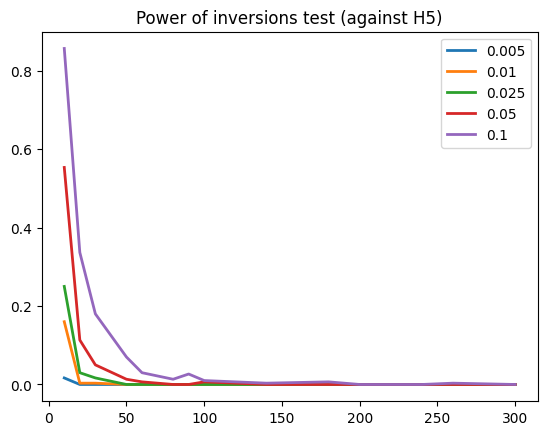

In [ ]:
i = 0
while i < len(p_inv_pt):
  x_i = []
  y_i = []
  for sample in p_inv_pt[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.title('Power of inversions test (against H5)')
plt.show()

# Альтернативная гипотеза Н6 (автокорреляция 1 порядка)

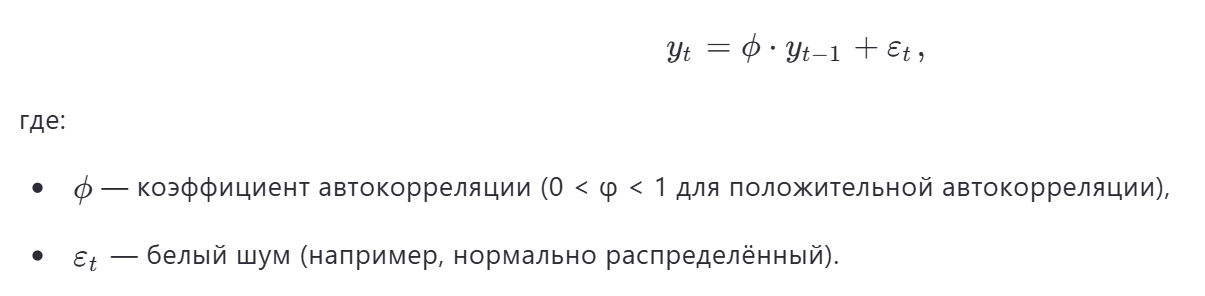

In [ ]:
data_art = []
#n = [10, 15, 20, 25, 30, 34, 38, 42, 46, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]
n = [10, 20, 30, 50, 60, 80, 90, 100, 140, 180, 200, 240, 260, 300]
for n_samples in n:
  for num in range (runs):
    size = n_samples
    phi = 0.8
    sigma = 1.0

    y = np.zeros(size)
    epsilon = np.random.normal(0, sigma, size)

    for t in range(1, size):
      y[t] = phi * y[t-1] + epsilon[t]

    data_art.append(y)


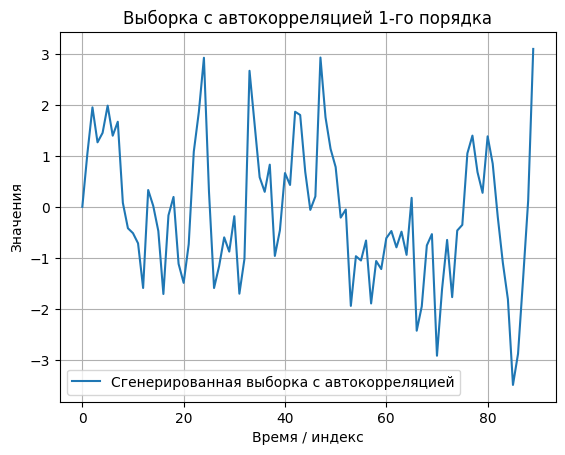

In [ ]:
# Визуализация
plt.plot(np.arange(len(data_art[2000])), data_art[2000], label='Сгенерированная выборка с автокорреляцией')
plt.xlabel('Время / индекс')
plt.ylabel('Значения')
plt.title('Выборка с автокорреляцией 1-го порядка')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# data_art = []
# n = [10, 15, 20, 25, 30, 34, 38, 42, 46, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]
# for n_samples in n:
#   for num in range (runs):
#     size = n_samples
#     phi1 = 0.2
#     phi2 = 0.3
#     sigma = 2.0
#     np.random.seed(42)
#     X = np.zeros(size)
#     X[0] = np.random.normal(0, sigma)
#     X[1] = np.random.normal(0, sigma)
#     epsilon = np.random.normal(0, sigma, size)
#     for t in range(2, size):
#       X[t] = phi1 * X[t - 1] + phi2 * X[t - 2] + epsilon[t]
#     data_art.append(X)

# # Визуализация
# plt.plot(np.arange(len(data_art[2000])), data_art[2000], label='Сгенерированная выборка с автокорреляцией')
# plt.xlabel('Время / индекс')
# plt.ylabel('Значения')
# plt.title('Выборка с автокорреляцией')
# plt.legend()
# plt.grid(True)
# plt.show()

Мощность теста сериальной корреляции

In [ ]:
p_sc_ac = []
for alpha in alphas:
  i = 0
  while i < len(data_art):
    power_sc = calculate_power_sc(data_art[i:(i + runs)], alpha, runs)
    power = (len(data_art[i]), alpha, power_sc)
    p_sc_ac.append(power)
    i += runs

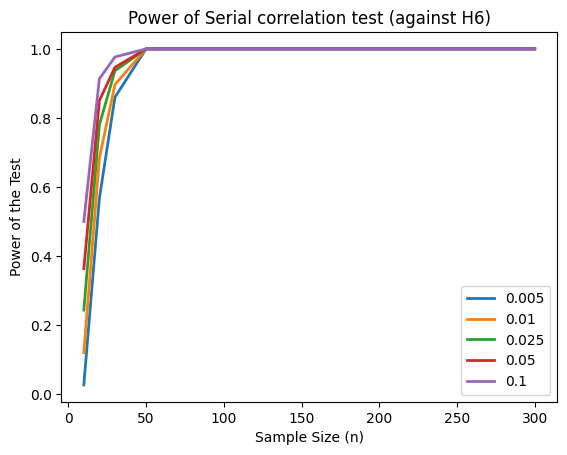

In [ ]:
i = 0
ser_corr = {}
while i < len(p_sc_ac):
  x_i = []
  y_i = []
  for sample in p_sc_ac[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  ser_corr[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')
plt.title('Power of Serial correlation test (against H6)')
plt.show()

Мощность рангового теста

In [ ]:
p_rvn_art = []
for alpha in alphas:
  i = 0
  while i < len(data_art):
    t = len(data_art[i])
    if t<=100:
      c_alpha = rvn_critical_values[(t, alpha)]
    else:
      c_alpha = 2 + (2/np.sqrt(t))*norm.ppf(alpha) #критическое значение из распределения N(2, 4/T)
    power_rvn = calculate_power_rvn(data_art[i:(i + runs)], c_alpha, runs)
    power = (t, alpha, power_rvn)
    p_rvn_art.append(power)
    i += runs
print(p_rvn_art)

[(10, 0.005, 0.15), (20, 0.005, 0.6366666666666667), (30, 0.005, 0.87), (50, 0.005, 0.9966666666666667), (60, 0.005, 1.0), (80, 0.005, 1.0), (90, 0.005, 1.0), (100, 0.005, 1.0), (140, 0.005, 1.0), (180, 0.005, 1.0), (200, 0.005, 1.0), (240, 0.005, 1.0), (260, 0.005, 1.0), (300, 0.005, 1.0), (10, 0.01, 0.22666666666666666), (20, 0.01, 0.72), (30, 0.01, 0.9066666666666666), (50, 0.01, 1.0), (60, 0.01, 1.0), (80, 0.01, 1.0), (90, 0.01, 1.0), (100, 0.01, 1.0), (140, 0.01, 1.0), (180, 0.01, 1.0), (200, 0.01, 1.0), (240, 0.01, 1.0), (260, 0.01, 1.0), (300, 0.01, 1.0), (10, 0.025, 0.3566666666666667), (20, 0.025, 0.8333333333333334), (30, 0.025, 0.94), (50, 0.025, 1.0), (60, 0.025, 1.0), (80, 0.025, 1.0), (90, 0.025, 1.0), (100, 0.025, 1.0), (140, 0.025, 1.0), (180, 0.025, 1.0), (200, 0.025, 1.0), (240, 0.025, 1.0), (260, 0.025, 1.0), (300, 0.025, 1.0), (10, 0.05, 0.48), (20, 0.05, 0.8833333333333333), (30, 0.05, 0.9666666666666667), (50, 0.05, 1.0), (60, 0.05, 1.0), (80, 0.05, 1.0), (90, 0.0

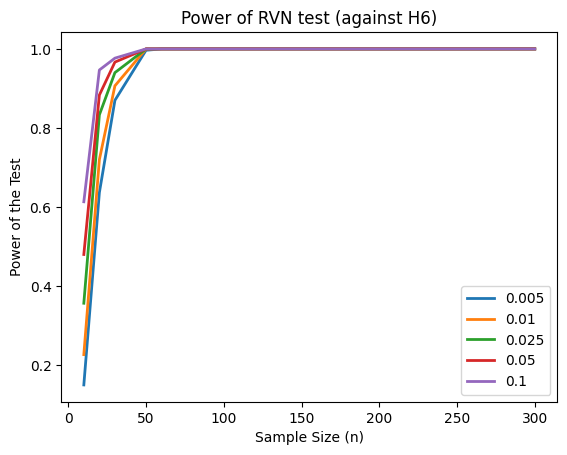

In [ ]:
rvn_res = {}
i = 0
while i < len(p_rvn_art):
  x_i = []
  y_i = []
  for sample in p_rvn_art[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  rvn_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')
plt.title('Power of RVN test (against H6)')
plt.show()

Мощность теста серий

In [ ]:
p_runs = []
for alpha in alphas:
  i = 0
  while i < len(data_art):
    t = len(data_art[i])
    power_runs = calculate_power_runs(data_art[i:(i + runs)], alpha, runs)
    power = (t, alpha, power_runs)
    p_runs.append(power)
    i += runs

In [ ]:
print(p_runs)

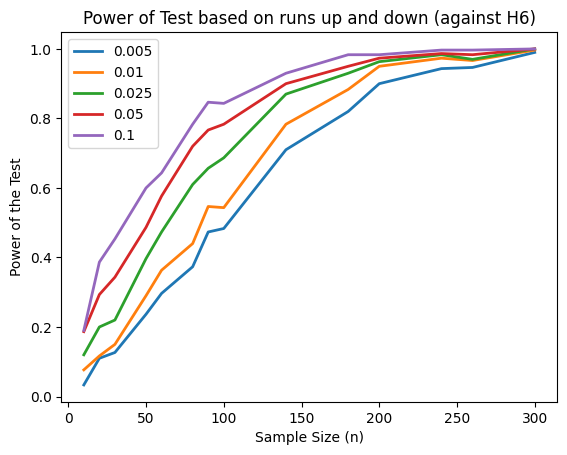

In [ ]:
i = 0
runs_res = {}
while i < len(p_runs):
  x_i = []
  y_i = []
  for sample in p_runs[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  runs_res[alpha] = (x_i, y_i)
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')
plt.title('Power of Test based on runs up and down (against H6)')
plt.show()

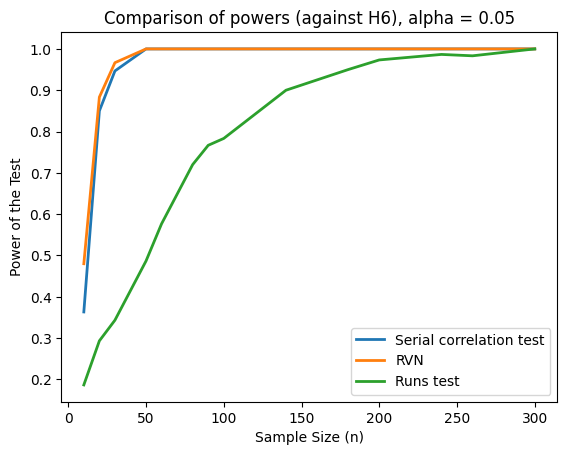

In [ ]:
i = 0
alpha = 0.05
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = runs_res[alpha][0]
Y3 = runs_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Runs test')
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')
plt.legend()
plt.title('Comparison of powers (against H6), alpha = 0.05')
plt.show()

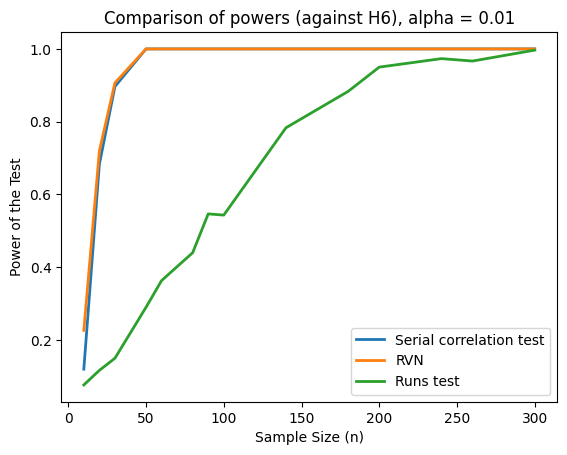

In [ ]:
i = 0
alpha = 0.01
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = runs_res[alpha][0]
Y3 = runs_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Runs test')
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')

plt.legend()
plt.title('Comparison of powers (against H6), alpha = 0.01')
plt.show()

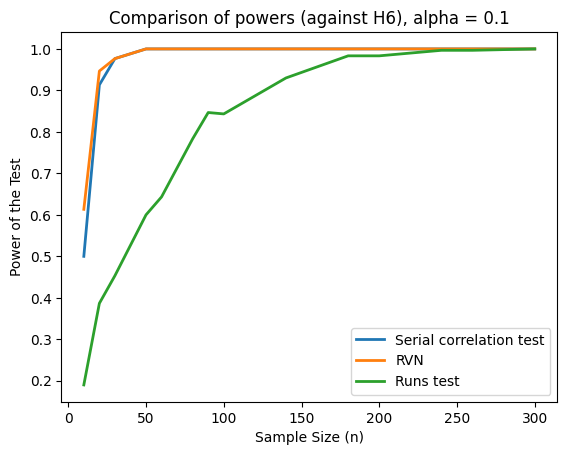

In [ ]:
i = 0
alpha = 0.1
x_i = ser_corr[alpha][0]
y_i = ser_corr[alpha][1]
plt.plot(x_i, y_i, linewidth=2, label = 'Serial correlation test')

X_i = rvn_res[alpha][0]
Y_i = rvn_res[alpha][1]
plt.plot(X_i, Y_i, linewidth=2, label = 'RVN')

X3 = runs_res[alpha][0]
Y3 = runs_res[alpha][1]
plt.plot(X3, Y3, linewidth=2, label = 'Runs test')
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')

plt.legend()
plt.title('Comparison of powers (against H6), alpha = 0.1')
plt.show()

In [ ]:
t_a_2 = 0.06270676000031
p_inv_art = []

for alpha in alphas:
  i = 0
  while i < len(data_art):
    power_inv = calculate_power_inv(data_art[i:(i + runs)], alpha, runs)
    power = (len(data_art[i]), alpha, power_inv)
    p_inv_art.append(power)
    i += runs

print(p_inv_art)

[(10, 0.005, 0.013333333333333334), (20, 0.005, 0.08), (30, 0.005, 0.11666666666666667), (50, 0.005, 0.13), (60, 0.005, 0.14333333333333334), (80, 0.005, 0.12666666666666668), (90, 0.005, 0.19333333333333333), (100, 0.005, 0.19), (140, 0.005, 0.20333333333333334), (180, 0.005, 0.13333333333333333), (200, 0.005, 0.18333333333333332), (240, 0.005, 0.17666666666666667), (260, 0.005, 0.16666666666666666), (300, 0.005, 0.17333333333333334), (10, 0.01, 0.043333333333333335), (20, 0.01, 0.10666666666666667), (30, 0.01, 0.14666666666666667), (50, 0.01, 0.14), (60, 0.01, 0.15333333333333332), (80, 0.01, 0.15333333333333332), (90, 0.01, 0.22333333333333333), (100, 0.01, 0.21666666666666667), (140, 0.01, 0.22333333333333333), (180, 0.01, 0.14), (200, 0.01, 0.20666666666666667), (240, 0.01, 0.18666666666666668), (260, 0.01, 0.18), (300, 0.01, 0.20333333333333334), (10, 0.025, 0.06666666666666667), (20, 0.025, 0.14333333333333334), (30, 0.025, 0.19333333333333333), (50, 0.025, 0.16333333333333333),

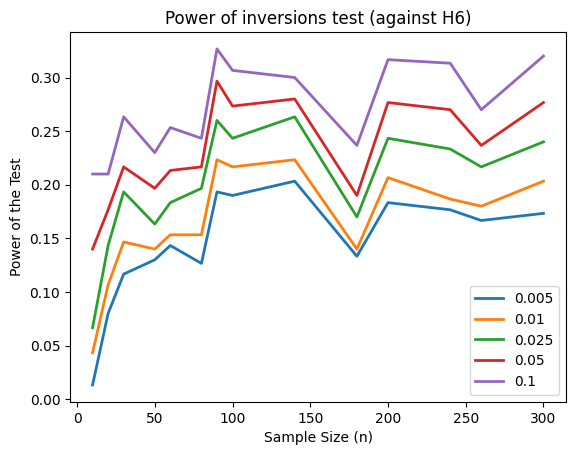

In [ ]:
i = 0
while i < len(p_inv_art):
  x_i = []
  y_i = []
  for sample in p_inv_art[i:(i+len(n))]:
    x_i.append(sample[0])
    y_i.append(sample[2])
  alpha = sample[1]
  plt.plot(x_i, y_i, linewidth=2, label = str(alpha))
  i += len(n)
plt.legend()
plt.xlabel('Sample Size (n)')
plt.ylabel('Power of the Test')
plt.title('Power of inversions test (against H6)')
plt.show()

# Работа с данными фондового рынка

Установим библиотеку yahoo finance

In [ ]:
!pip install --upgrade yfinance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.4/118.4 kB 2.0 MB/s eta 0:00:00
  Attempting uninstall: yfinance
    Found existing installation: yfinance 0.2.62
    Uninstalling yfinance-0.2.62:
      Successfully uninstalled yfinance-0.2.62


Получим цену акции с интервалом 1 день (всего 250 наблюдений - год торгов на бирже)

In [ ]:
tickers = ['GOOGL', 'CRDO']

start = "2024-06-17"
end = "2025-06-17"

day_data = pd.DataFrame()
for ticker in tickers:
    try:
        temp = pd.DataFrame(yf.download(ticker, start, end))
        if not temp.empty:
            day_data[ticker] = temp["Close"]
    except:
        print("data not found")

<ipython-input-68-980354253>:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = pd.DataFrame(yf.download(ticker, start, end))
[*********************100%***********************]  1 of 1 completed
<ipython-input-68-980354253>:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = pd.DataFrame(yf.download(ticker, start, end))
[*********************100%***********************]  1 of 1 completed


In [ ]:
day_data
day_data.to_csv('day_data.csv')

Получим цену акции с интервалом 1.5 часа (за последние 60 дней, возьмем 250 последних наблюдений)

In [ ]:
one_half_hour_data = pd.DataFrame()
for ticker in tickers:
  temp = yf.download(
      tickers=ticker,
      period="60d",
      interval="90m",
      progress=False)
  one_half_hour_data[ticker] = temp["Close"]

<ipython-input-70-3436662206>:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(
<ipython-input-70-3436662206>:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(


In [ ]:
one_half_hour_data = one_half_hour_data.tail(250)
one_half_hour_data.to_csv('one_half_hour_data.csv')

In [ ]:
one_half_hour_data

,GOOGL,CRDO
Datetime,,
2025-04-07 13:30:00+00:00,148.229996,35.610001
2025-04-07 15:00:00+00:00,145.690002,34.950001
2025-04-07 16:30:00+00:00,148.630005,35.950001
2025-04-07 18:00:00+00:00,145.690002,35.130001
2025-04-07 19:30:00+00:00,146.800003,35.860001
...,...,...
2025-06-17 13:30:00+00:00,176.119995,79.529999
2025-06-17 15:00:00+00:00,177.059998,79.029999
2025-06-17 16:30:00+00:00,176.289993,78.430000


Получим цену акции с интервалом 1 час (за последние 60 дней, возьмем 250 последних наблюдений)

In [ ]:
hour_data = pd.DataFrame()
for ticker in tickers:
  temp = yf.download(
      tickers=ticker,
      period="60d",
      interval="1h",
      progress=False)
  hour_data[ticker] = temp["Close"]

<ipython-input-74-3051975582>:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(
<ipython-input-74-3051975582>:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(


In [ ]:
hour_data = hour_data.tail(250)
hour_data.to_csv('hour_data.csv')

In [ ]:
hour_data

,GOOGL,CRDO
Datetime,,
2025-04-28 15:30:00+00:00,158.940002,42.043999
2025-04-28 16:30:00+00:00,158.830002,42.500000
2025-04-28 17:30:00+00:00,159.350006,42.630001
2025-04-28 18:30:00+00:00,160.074997,43.181702
2025-04-28 19:30:00+00:00,160.610001,43.020000
...,...,...
2025-06-17 15:30:00+00:00,177.059998,79.029999
2025-06-17 16:30:00+00:00,176.705002,79.129997
2025-06-17 17:30:00+00:00,176.154999,78.779999


Получим цену акции с интервалом 30 минут (за последние 20 дней, возьмем 250 последних наблюдений)

In [ ]:
thirty_minute_data = pd.DataFrame()
for ticker in tickers:
  temp = yf.download(
      tickers=ticker,
      period="20d",
      interval="30m",
      progress=False)
  thirty_minute_data[ticker] = temp["Close"]

<ipython-input-77-2446704383>:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(
<ipython-input-77-2446704383>:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(


In [ ]:
thirty_minute_data = thirty_minute_data.tail(250)
thirty_minute_data.to_csv('thirty_minute_data.csv')

In [ ]:
thirty_minute_data

,GOOGL,CRDO
Datetime,,
2025-05-20 18:30:00+00:00,163.710007,61.740002
2025-05-20 19:00:00+00:00,163.681702,61.830002
2025-05-20 19:30:00+00:00,164.000000,62.119999
2025-05-21 13:30:00+00:00,167.990005,62.310001
2025-05-21 14:00:00+00:00,169.320007,61.810001
...,...,...
2025-06-17 17:30:00+00:00,176.289993,78.430000
2025-06-17 18:00:00+00:00,176.154999,78.779999
2025-06-17 18:30:00+00:00,176.460007,78.940002


Получим цену акции с интервалом 1 минута (за последние 7 дней, возьмем 250 последних наблюдений)

In [ ]:
minute_data = pd.DataFrame()
for ticker in tickers:
  temp = yf.download(
      tickers=ticker,
      period="7d",
      interval="1m",
      progress=False)
  minute_data[ticker] = temp["Close"]

<ipython-input-79-3356614416>:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(
<ipython-input-79-3356614416>:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(


In [ ]:
minute_data = minute_data.tail(250)
minute_data.to_csv('minute_data.csv')

In [ ]:
minute_data

,GOOGL,CRDO
Datetime,,
2025-06-17 15:50:00+00:00,176.954895,79.154999
2025-06-17 15:51:00+00:00,177.059998,79.235001
2025-06-17 15:52:00+00:00,177.089996,79.275002
2025-06-17 15:53:00+00:00,177.139999,79.254997
2025-06-17 15:54:00+00:00,177.089996,79.245003
...,...,...
2025-06-17 19:55:00+00:00,176.100006,79.885002
2025-06-17 19:56:00+00:00,176.050003,79.894997
2025-06-17 19:57:00+00:00,175.925003,79.839897


In [ ]:
!pip install PyPortfolioOpt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 220.1/220.1 kB 10.3 MB/s eta 0:00:00


In [ ]:
from pypfopt import expected_returns

In [ ]:
day_data = pd.read_csv('day_data.csv')
hour_data = pd.read_csv('hour_data.csv')
minute_data = pd.read_csv('minute_data.csv')
one_half_hour_data = pd.read_csv('one_half_hour_data.csv')
thirty_minute_data = pd.read_csv('thirty_minute_data.csv')

In [ ]:
day_data = expected_returns.returns_from_prices(day_data['GOOGL'], log_returns=True) #вычисление доходностей
hour_data = expected_returns.returns_from_prices(hour_data['GOOGL'], log_returns=True)
minute_data = expected_returns.returns_from_prices(minute_data['GOOGL'], log_returns=True)
one_half_hour_data = expected_returns.returns_from_prices(one_half_hour_data['GOOGL'], log_returns=True)
thirty_minute_data = expected_returns.returns_from_prices(thirty_minute_data['GOOGL'], log_returns=True)

In [ ]:
day_data

,GOOGL
1,-0.012205
2,0.006887
3,0.018712
4,-0.002285
5,0.026485
...,...
245,0.014153
246,-0.007023
247,-0.009347
248,-0.005880


Построим графики цен акции в соответствии с временными интервалами


In [ ]:
data_times = ['every 1d', 'every 1.5h', 'every 1h', 'every 30m', 'every 1m']
data_frames = [day_data, one_half_hour_data, hour_data, thirty_minute_data, minute_data]

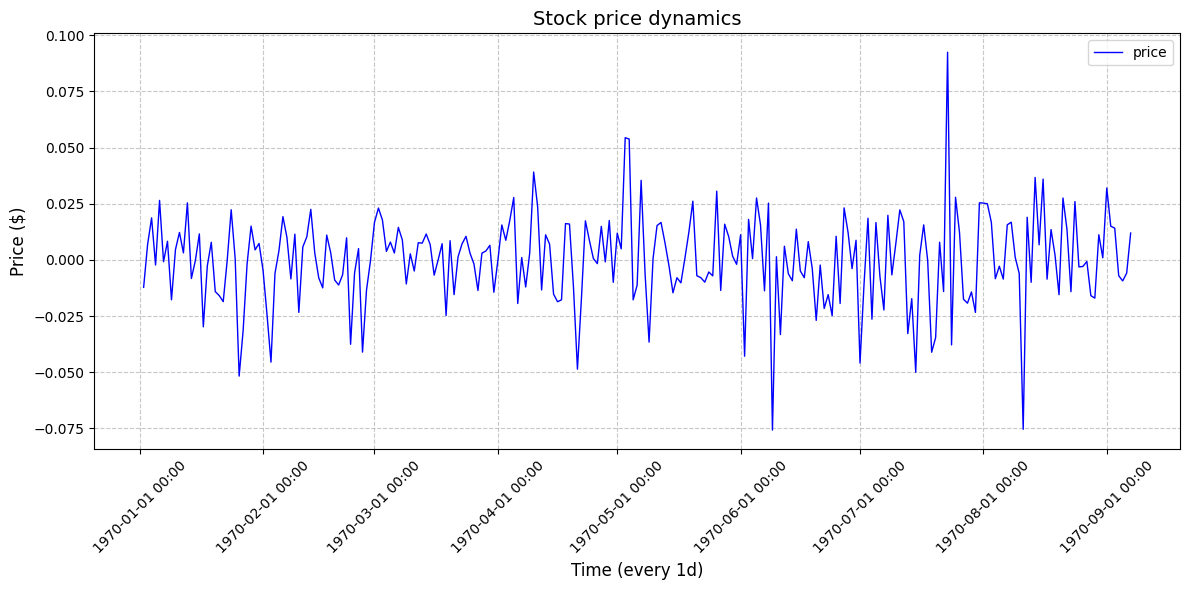

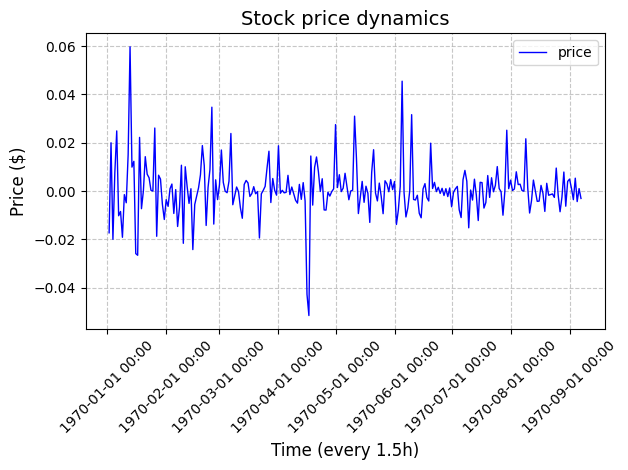

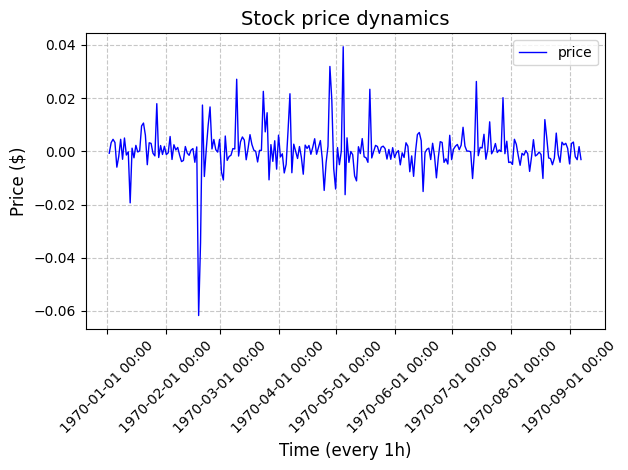

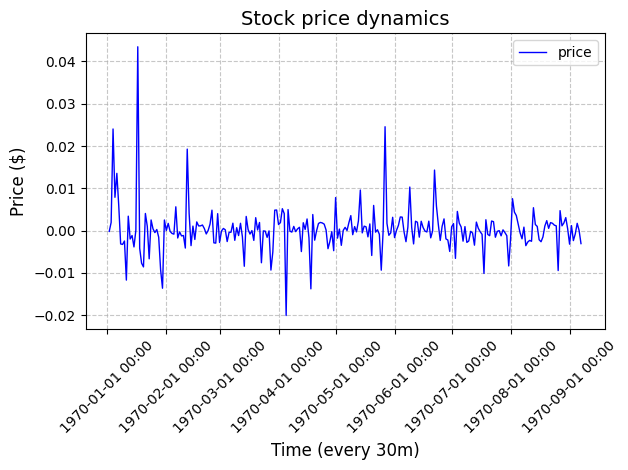

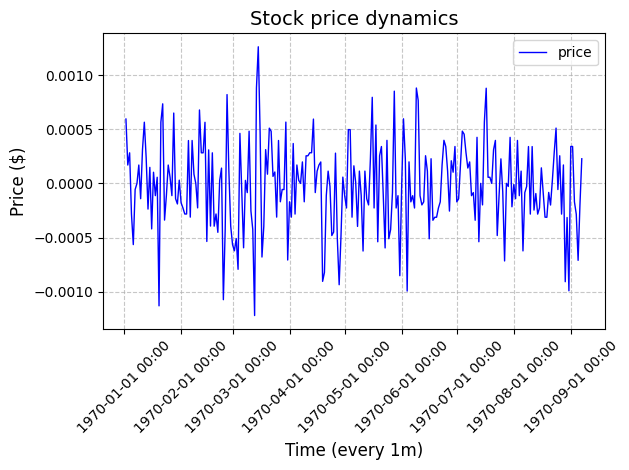

In [ ]:
import matplotlib.dates as mdates

plt.figure(figsize=(12, 6))
i = 0
for df in data_frames:
  plt.plot(df.index, df, label='price', color='blue', linewidth=1)

  plt.title('Stock price dynamics', fontsize=14)
  plt.xlabel(f'Time ({data_times[i]})', fontsize=12)
  i += 1
  plt.ylabel('Price ($)', fontsize=12)
  plt.grid(True, linestyle='--', alpha=0.7)

  ax = plt.gca()
  ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
  ax.xaxis.set_major_locator(mdates.AutoDateLocator())
  plt.xticks(rotation=45)

  plt.legend()
  plt.tight_layout()
  plt.show()

# Рассмотрим другие акции с биржи NASDAQ

Получим цену акции с интервалом 1 день (всего 250 наблюдений - год торгов на бирже)

In [ ]:
tickers = ['NVDA', 'UAA', 'BBIO']

start = "2024-06-20"
end = "2025-06-20"

day_data_new = pd.DataFrame()
for ticker in tickers:
    try:
        temp = pd.DataFrame(yf.download(ticker, start, end))
        if not temp.empty:
            day_data_new[ticker] = temp["Close"]
    except:
        print("data not found")

/tmp/ipython-input-301-1344242711.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = pd.DataFrame(yf.download(ticker, start, end))
[*********************100%***********************]  1 of 1 completed
/tmp/ipython-input-301-1344242711.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = pd.DataFrame(yf.download(ticker, start, end))
[*********************100%***********************]  1 of 1 completed
/tmp/ipython-input-301-1344242711.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = pd.DataFrame(yf.download(ticker, start, end))
[*********************100%***********************]  1 of 1 completed


In [ ]:
day_data_new
#day_data_new.to_csv('day_data_new.csv')

,LEU
Date,
2024-06-20,42.630001
2024-06-21,43.750000
2024-06-24,43.799999
2024-06-25,44.610001
2024-06-26,44.000000
...,...
2025-06-12,158.440002
2025-06-13,162.240005
2025-06-16,169.929993


Получим цену акции с интервалом 1.5 часа (за последние 60 дней, возьмем 250 последних наблюдений)

In [ ]:
one_half_hour_data_new = pd.DataFrame()
for ticker in tickers:
  temp = yf.download(
      tickers=ticker,
      period="60d",
      interval="90m",
      progress=False)
  one_half_hour_data_new[ticker] = temp["Close"]

/tmp/ipython-input-242-3034336005.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(


In [ ]:
one_half_hour_data_new = one_half_hour_data_new.tail(250)
#one_half_hour_data_new.to_csv('one_half_hour_data_new.csv')

Получим цену акции с интервалом 1 час (за последние 60 дней, возьмем 250 последних наблюдений)

In [ ]:
hour_data_new = pd.DataFrame()
for ticker in tickers:
  temp = yf.download(
      tickers=ticker,
      period="60d",
      interval="1h",
      progress=False)
  hour_data_new[ticker] = temp["Close"]

/tmp/ipython-input-244-1297166323.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(


In [ ]:
hour_data_new = hour_data_new.tail(250)
#hour_data_new.to_csv('hour_data_new.csv')

Получим цену акции с интервалом 30 минут (за последние 20 дней, возьмем 250 последних наблюдений)

In [ ]:
thirty_minute_data_new = pd.DataFrame()
for ticker in tickers:
  temp = yf.download(
      tickers=ticker,
      period="20d",
      interval="30m",
      progress=False)
  thirty_minute_data_new[ticker] = temp["Close"]

/tmp/ipython-input-246-12870504.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(


In [ ]:
thirty_minute_data_new = thirty_minute_data_new.tail(250)
#thirty_minute_data_new.to_csv('thirty_minute_data_new.csv')

Получим цену акции с интервалом 1 минута (за последние 7 дней, возьмем 250 последних наблюдений)

In [ ]:
minute_data_new = pd.DataFrame()
for ticker in tickers:
  temp = yf.download(
      tickers=ticker,
      period="7d",
      interval="1m",
      progress=False)
  minute_data_new[ticker] = temp["Close"]

/tmp/ipython-input-248-1510114255.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  temp = yf.download(


In [ ]:
minute_data_new = minute_data_new.tail(250)
#minute_data_new.to_csv('minute_data_new.csv')

In [ ]:
day_data_new = pd.read_csv('day_data_new.csv')
hour_data_new = pd.read_csv('hour_data_new.csv')
minute_data_new = pd.read_csv('minute_data_new.csv')
one_half_hour_data_new = pd.read_csv('one_half_hour_data_new.csv')
thirty_minute_data_new = pd.read_csv('thirty_minute_data_new.csv')

In [ ]:
day_data_new

,Date,NVDA,GOOGL,TSLA,UAA,BBIO,BBUC
0,2024-06-20,130.738708,175.450104,181.570007,6.99,27.049999,19.633680
1,2024-06-21,126.530029,178.764053,183.009995,6.99,27.360001,19.246563
2,2024-06-24,118.072701,178.356018,182.580002,7.13,23.000000,18.938856
3,2024-06-25,126.050163,183.142838,187.350006,6.94,23.379999,18.333370
4,2024-06-26,126.360092,182.993561,196.369995,7.04,23.559999,19.236637
...,...,...,...,...,...,...,...
245,2025-06-12,145.000000,175.699997,319.109985,6.84,39.650002,28.389999
246,2025-06-13,141.970001,174.669998,325.309998,6.60,39.779999,28.190001
247,2025-06-16,144.690002,176.770004,329.130005,6.64,41.139999,28.059999
248,2025-06-17,144.119995,175.949997,316.350006,6.33,40.070000,28.070000


In [ ]:
data_times_new = ['every 1d', 'every 1.5h', 'every 1h', 'every 30m', 'every 1m']
data_frames_new = [day_data_new, one_half_hour_data_new, hour_data_new, thirty_minute_data_new, minute_data_new]

In [ ]:
day_data_new

,NVDA
1,-0.032721
2,-0.069179
3,0.065379
4,0.002456
5,-0.019251
...,...
245,0.015079
246,-0.021118
247,0.018978
248,-0.003947


In [ ]:
day_data_new = expected_returns.returns_from_prices(day_data_new['TSLA'], log_returns=True)
hour_data_new = expected_returns.returns_from_prices(hour_data_new['TSLA'], log_returns=True)
minute_data_new = expected_returns.returns_from_prices(minute_data_new['TSLA'], log_returns=True)
one_half_hour_data_new = expected_returns.returns_from_prices(one_half_hour_data_new['TSLA'], log_returns=True)
thirty_minute_data_new = expected_returns.returns_from_prices(thirty_minute_data_new['TSLA'], log_returns=True)

In [ ]:
day_data_new

,TSLA
1,0.007899
2,-0.002352
3,0.025790
4,0.047022
5,0.005333
...,...
245,-0.022680
246,0.019243
247,0.011674
248,-0.039604


In [ ]:
print(len(day_data_new))
print(len(one_half_hour_data_new))
print(len(hour_data_new))
print(len(thirty_minute_data_new))
print(len(minute_data_new))

249
249
249
249
249


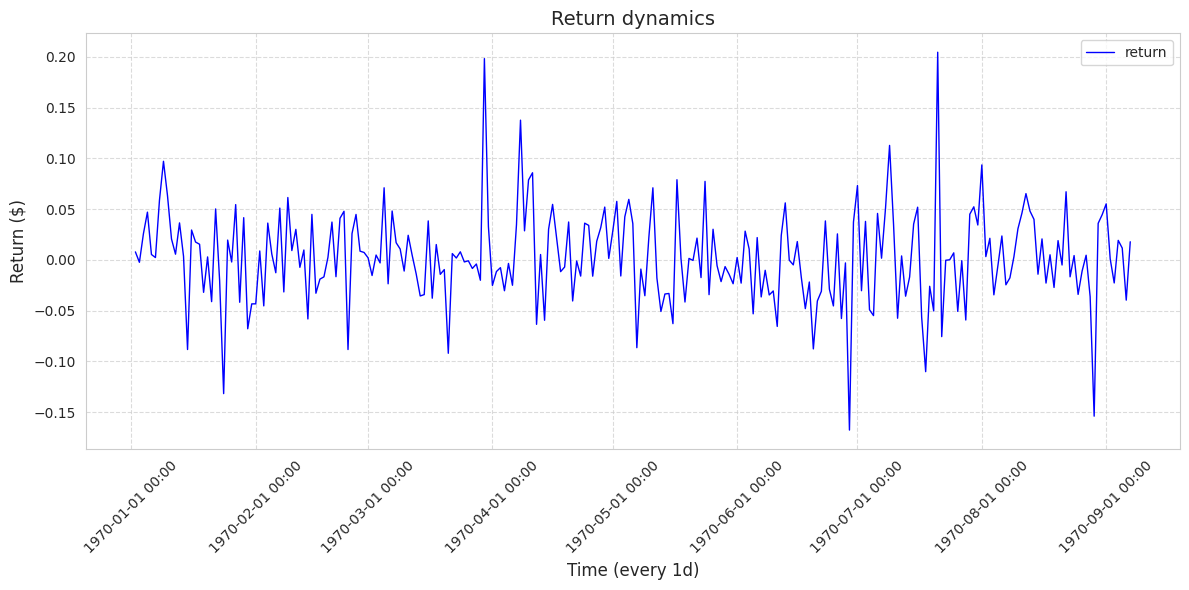

In [ ]:
import matplotlib.dates as mdates

plt.figure(figsize=(12, 6))
i = 0

plt.plot(day_data_new.index, day_data_new, label='return', color='blue', linewidth=1)

plt.title('Return dynamics', fontsize=14)
plt.xlabel(f'Time ({data_times[i]})', fontsize=12)
i += 1
plt.ylabel('Return ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=45)

plt.legend()
plt.tight_layout()
plt.show()

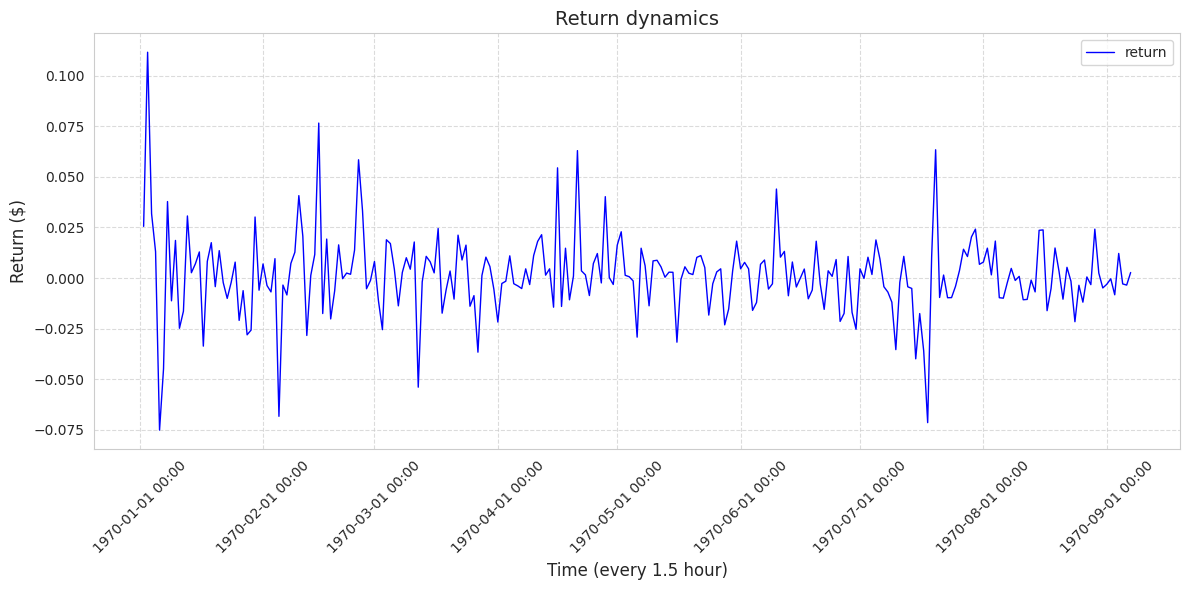

In [ ]:
import matplotlib.dates as mdates

plt.figure(figsize=(12, 6))
i = 0

plt.plot(one_half_hour_data_new.index, one_half_hour_data_new, label='return', color='blue', linewidth=1)

plt.title('Return dynamics', fontsize=14)
plt.xlabel(f'Time (every 1.5 hour)', fontsize=12)
i += 1
plt.ylabel('Return ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=45)

plt.legend()
plt.tight_layout()
plt.show()

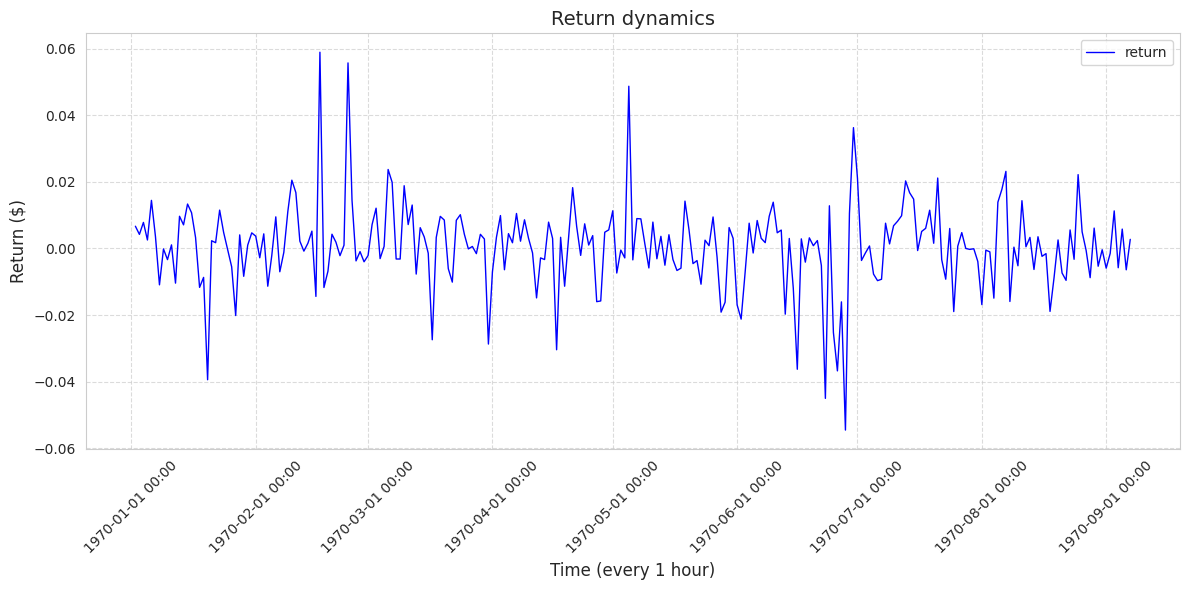

In [ ]:
import matplotlib.dates as mdates

plt.figure(figsize=(12, 6))
i = 0

plt.plot(hour_data_new.index, hour_data_new, label='return', color='blue', linewidth=1)

plt.title('Return dynamics', fontsize=14)
plt.xlabel(f'Time (every 1 hour)', fontsize=12)
i += 1
plt.ylabel('Return ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=45)

plt.legend()
plt.tight_layout()
plt.show()

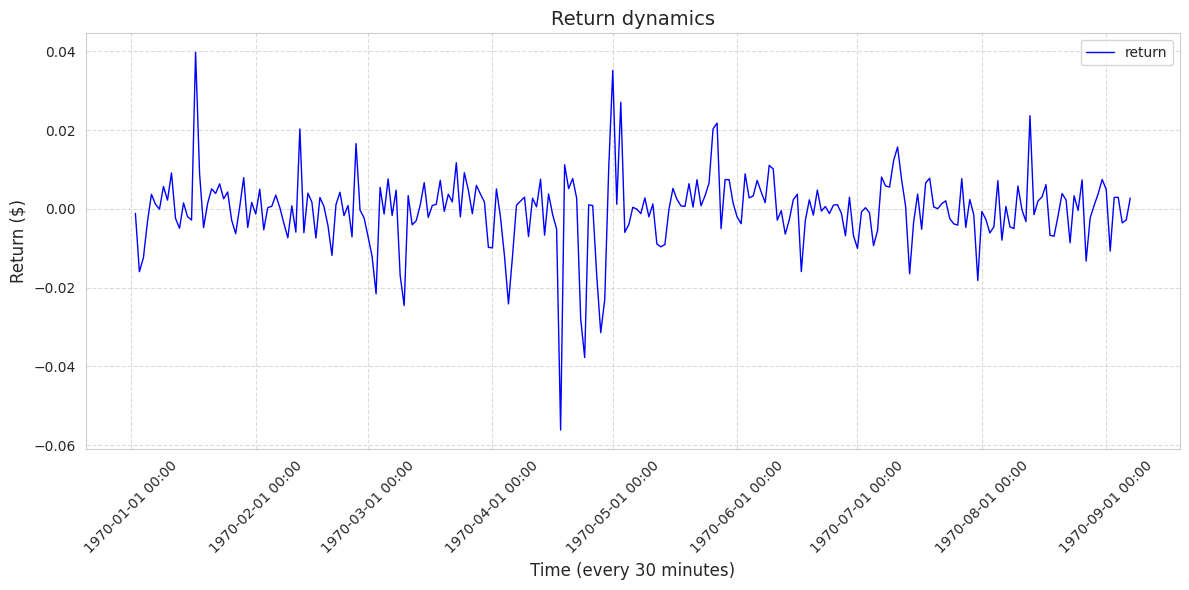

In [ ]:
import matplotlib.dates as mdates

plt.figure(figsize=(12, 6))
i = 0

plt.plot(thirty_minute_data_new.index, thirty_minute_data_new, label='return', color='blue', linewidth=1)

plt.title('Return dynamics', fontsize=14)
plt.xlabel(f'Time (every 30 minutes)', fontsize=12)
i += 1
plt.ylabel('Return ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=45)

plt.legend()
plt.tight_layout()
plt.show()

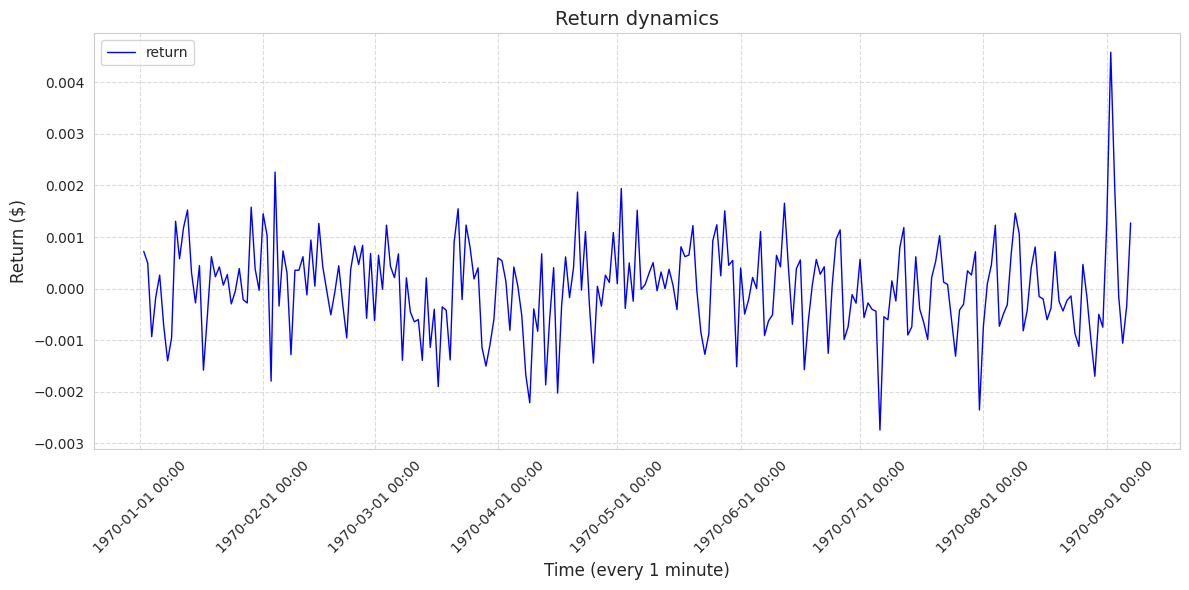

In [ ]:
import matplotlib.dates as mdates

plt.figure(figsize=(12, 6))
i = 0

plt.plot(minute_data_new.index, minute_data_new, label='return', color='blue', linewidth=1)

plt.title('Return dynamics', fontsize=14)
plt.xlabel(f'Time (every 1 minute)', fontsize=12)
i += 1
plt.ylabel('Return ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=45)

plt.legend()
plt.tight_layout()
plt.show()

# Применим тесты, рассмотренные выше, к данным по ценам акции GOOGL, полученными с различными временными промежутками

1. Ежедневные наблюдения

In [ ]:
results = pd.DataFrame(columns = ['Тест', 'Уровень значимости alpha', 'Частота наблюдений', 'Результат'])


Сериальная корреляция

In [ ]:
day_data_new

,TSLA
1,0.007899
2,-0.002352
3,0.025790
4,0.047022
5,0.005333
...,...
245,-0.022680
246,0.019243
247,0.011674
248,-0.039604


In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Тест сериальной корреляции: \n')
for alpha in alphas:
  x = list(day_data_new)
  sc_result = serial_corr_test(x, alpha)
  print(sc_result)
  sc_result = d[sc_result]
  new_row = {'Тест': 'Cериальная корреляция', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в день', 'Результат': sc_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {sc_result}')

Тест сериальной корреляции: 

True
на уровне значимости 0.005: выборка повторна
True
на уровне значимости 0.01: выборка повторна
True
на уровне значимости 0.025: выборка повторна
True
на уровне значимости 0.05: выборка повторна
True
на уровне значимости 0.1: выборка повторна


/tmp/ipython-input-450-974807229.py:10: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,1 день,выборка повторна
1,Cериальная корреляция,0.010,1 день,выборка повторна
2,Cериальная корреляция,0.025,1 день,выборка повторна
3,Cериальная корреляция,0.050,1 день,выборка повторна
4,Cериальная корреляция,0.100,1 день,выборка повторна


RVN тест

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('RVN тест: \n')
x = list(day_data_new)
rvn = calculate_rvn(x)
t = len(x)
for alpha in alphas:
  c_alpha = norm.ppf(alpha, loc = 2, scale = np.sqrt(4/t)) #критическое значение из распределения N(2, 4/T)
  if rvn < c_alpha:
    rvn_result = False
  else:
    rvn_result = True
  rvn_result = d[rvn_result]
  new_row = {'Тест': 'RVN', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в день', 'Результат': rvn_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(rvn, c_alpha, t)
  print(f'на уровне значимости {alpha}: {rvn_result}')

RVN тест: 

1.9754349008938983 1.6735269010258969 249
на уровне значимости 0.005: выборка повторна
1.9754349008938983 1.705147387412851 249
на уровне значимости 0.01: выборка повторна
1.9754349008938983 1.751584658568477 249
на уровне значимости 0.025: выборка повторна
1.9754349008938983 1.7915232736075417 249
на уровне значимости 0.05: выборка повторна
1.9754349008938983 1.8375699389233553 249
на уровне значимости 0.1: выборка повторна


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,1 день,выборка повторна
1,Cериальная корреляция,0.010,1 день,выборка повторна
2,Cериальная корреляция,0.025,1 день,выборка повторна
3,Cериальная корреляция,0.050,1 день,выборка повторна
4,Cериальная корреляция,0.100,1 день,выборка повторна
5,RVN,0.005,1 день,выборка повторна
6,RVN,0.010,1 день,выборка повторна
7,RVN,0.025,1 день,выборка повторна
8,RVN,0.050,1 день,выборка повторна
9,RVN,0.100,1 день,выборка повторна


Тест серий

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Тест серий: \n')
for alpha in alphas:
  runs_result = runs_test(day_data_new, alpha)
  runs_result = d[runs_result]
  new_row = {'Тест': 'Тест серий', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в день', 'Результат': runs_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {runs_result}')

Тест серий: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,1 день,выборка повторна
1,Cериальная корреляция,0.010,1 день,выборка повторна
2,Cериальная корреляция,0.025,1 день,выборка повторна
3,Cериальная корреляция,0.050,1 день,выборка повторна
4,Cериальная корреляция,0.100,1 день,выборка повторна
5,RVN,0.005,1 день,выборка повторна
6,RVN,0.010,1 день,выборка повторна
7,RVN,0.025,1 день,выборка повторна
8,RVN,0.050,1 день,выборка повторна
9,RVN,0.100,1 день,выборка повторна


Тест инверсий

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Критерий инверсий: \n')
for alpha in alphas:
  x = list(day_data_new)
  inv_result = inv_test(x, alpha)
  inv_result = d[inv_result]
  new_row = {'Тест': 'Тест инверсий', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в день', 'Результат': inv_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {inv_result}')

Критерий инверсий: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,раз в день,выборка повторна
1,Cериальная корреляция,0.010,раз в день,выборка повторна
2,Cериальная корреляция,0.025,раз в день,выборка повторна
3,Cериальная корреляция,0.050,раз в день,выборка повторна
4,Cериальная корреляция,0.100,раз в день,выборка повторна
5,RVN,0.005,раз в день,выборка повторна
6,RVN,0.010,раз в день,выборка повторна
7,RVN,0.025,раз в день,выборка повторна
8,RVN,0.050,раз в день,выборка повторна
9,RVN,0.100,раз в день,выборка повторна


2. Наблюдения каждые 1.5 часа

In [ ]:
results = pd.DataFrame(columns = ['Тест', 'Уровень значимости alpha', 'Частота наблюдений', 'Результат'])

Сериальная корреляция

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Тест сериальной корреляции: \n')
for alpha in alphas:
  x = list(one_half_hour_data_new)
  sc_result = serial_corr_test(x, alpha)
  sc_result = d[sc_result]
  new_row = {'Тест': 'Cериальная корреляция', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в 1.5 часа', 'Результат': sc_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {sc_result}')

Тест сериальной корреляции: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка НЕ повторна


/tmp/ipython-input-456-3663509388.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,раз в 1.5 часа,выборка повторна
1,Cериальная корреляция,0.010,раз в 1.5 часа,выборка повторна
2,Cериальная корреляция,0.025,раз в 1.5 часа,выборка повторна
3,Cериальная корреляция,0.050,раз в 1.5 часа,выборка повторна
4,Cериальная корреляция,0.100,раз в 1.5 часа,выборка НЕ повторна


RVN тест

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('RVN тест: \n')
x = list(one_half_hour_data_new)
rvn = calculate_rvn(x)
t = len(x)
for alpha in alphas:
  c_alpha = norm.ppf(alpha, loc = 2, scale = np.sqrt(4/t)) #критическое значение из распределения N(2, 4/T)
  if rvn < c_alpha:
    rvn_result = False
  else:
    rvn_result = True
  rvn_result = d[rvn_result]
  new_row = {'Тест': 'RVN', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в 1.5 часа', 'Результат': rvn_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {rvn_result}')

RVN тест: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,раз в 1.5 часа,выборка повторна
1,Cериальная корреляция,0.010,раз в 1.5 часа,выборка повторна
2,Cериальная корреляция,0.025,раз в 1.5 часа,выборка повторна
3,Cериальная корреляция,0.050,раз в 1.5 часа,выборка повторна
4,Cериальная корреляция,0.100,раз в 1.5 часа,выборка НЕ повторна
5,RVN,0.005,раз в 1.5 часа,выборка повторна
6,RVN,0.010,раз в 1.5 часа,выборка повторна
7,RVN,0.025,раз в 1.5 часа,выборка повторна
8,RVN,0.050,раз в 1.5 часа,выборка повторна
9,RVN,0.100,раз в 1.5 часа,выборка повторна


Тест серий

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Тест серий: \n')
for alpha in alphas:
  runs_result = runs_test(one_half_hour_data_new, alpha)
  runs_result = d[runs_result]
  new_row = {'Тест': 'Тест серий', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в 1.5 часа', 'Результат': runs_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {runs_result}')

Тест серий: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,раз в 1.5 часа,выборка повторна
1,Cериальная корреляция,0.010,раз в 1.5 часа,выборка повторна
2,Cериальная корреляция,0.025,раз в 1.5 часа,выборка повторна
3,Cериальная корреляция,0.050,раз в 1.5 часа,выборка повторна
4,Cериальная корреляция,0.100,раз в 1.5 часа,выборка НЕ повторна
5,RVN,0.005,раз в 1.5 часа,выборка повторна
6,RVN,0.010,раз в 1.5 часа,выборка повторна
7,RVN,0.025,раз в 1.5 часа,выборка повторна
8,RVN,0.050,раз в 1.5 часа,выборка повторна
9,RVN,0.100,раз в 1.5 часа,выборка повторна


Критерий инверсий

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Критерий инверсий: \n')
for alpha in alphas:
  x = list(one_half_hour_data_new)
  inv_result = inv_test(x, alpha)
  inv_result = d[inv_result]
  new_row = {'Тест': 'Тест инверсий', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в 1.5 часа', 'Результат': inv_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {inv_result}')

Критерий инверсий: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,раз в 1.5 часа,выборка повторна
1,Cериальная корреляция,0.010,раз в 1.5 часа,выборка повторна
2,Cериальная корреляция,0.025,раз в 1.5 часа,выборка повторна
3,Cериальная корреляция,0.050,раз в 1.5 часа,выборка повторна
4,Cериальная корреляция,0.100,раз в 1.5 часа,выборка НЕ повторна
5,RVN,0.005,раз в 1.5 часа,выборка повторна
6,RVN,0.010,раз в 1.5 часа,выборка повторна
7,RVN,0.025,раз в 1.5 часа,выборка повторна
8,RVN,0.050,раз в 1.5 часа,выборка повторна
9,RVN,0.100,раз в 1.5 часа,выборка повторна


3. Наблюдения каждый час

Сериальная корреляция

In [ ]:
results = pd.DataFrame(columns = ['Тест', 'Уровень значимости alpha', 'Частота наблюдений', 'Результат'])

In [ ]:
hour_data_new

,TSLA
1,0.006676
2,0.004228
3,0.007820
4,0.002545
5,0.014438
...,...
245,0.011274
246,-0.005785
247,0.005815
248,-0.006407


In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Тест сериальной корреляции: \n')
for alpha in alphas:
  x = list(hour_data_new)
  sc_result = serial_corr_test(x, alpha)
  sc_result = d[sc_result]
  new_row = {'Тест': 'Cериальная корреляция', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в час', 'Результат': sc_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {sc_result}')

Тест сериальной корреляции: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка НЕ повторна
на уровне значимости 0.1: выборка НЕ повторна


/tmp/ipython-input-465-859081885.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,1 час,выборка повторна
1,Cериальная корреляция,0.010,1 час,выборка повторна
2,Cериальная корреляция,0.025,1 час,выборка повторна
3,Cериальная корреляция,0.050,1 час,выборка НЕ повторна
4,Cериальная корреляция,0.100,1 час,выборка НЕ повторна


RVN тест

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('RVN тест: \n')
x = list(hour_data_new)
rvn = calculate_rvn(x)
t = len(x)
for alpha in alphas:
  c_alpha = norm.ppf(alpha, loc = 2, scale = np.sqrt(4/t)) #критическое значение из распределения N(2, 4/T)
  if rvn < c_alpha:
    rvn_result = False
  else:
    rvn_result = True
  print(rvn, c_alpha)
  rvn_result = d[rvn_result]
  new_row = {'Тест': 'RVN', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в час', 'Результат': rvn_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {rvn_result}')

RVN тест: 

1.7434558880684026 1.6735269010258969
на уровне значимости 0.005: выборка повторна
1.7434558880684026 1.705147387412851
на уровне значимости 0.01: выборка повторна
1.7434558880684026 1.751584658568477
на уровне значимости 0.025: выборка НЕ повторна
1.7434558880684026 1.7915232736075417
на уровне значимости 0.05: выборка НЕ повторна
1.7434558880684026 1.8375699389233553
на уровне значимости 0.1: выборка НЕ повторна


Тест серий

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Тест серий: \n')
for alpha in alphas:
  runs_result = runs_test(hour_data_new, alpha)
  runs_result = d[runs_result]
  new_row = {'Тест': 'Тест серий', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в час', 'Результат': runs_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {runs_result}')

Тест серий: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


Критерий инверсий

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Критерий инверсий: \n')
for alpha in alphas:
  x = list(hour_data_new)
  inv_result = inv_test(x, alpha)
  inv_result = d[inv_result]
  new_row = {'Тест': 'Тест инверсий', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в час', 'Результат': inv_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {inv_result}')

Критерий инверсий: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,раз в час,выборка повторна
1,Cериальная корреляция,0.010,раз в час,выборка повторна
2,Cериальная корреляция,0.025,раз в час,выборка повторна
3,Cериальная корреляция,0.050,раз в час,выборка НЕ повторна
4,Cериальная корреляция,0.100,раз в час,выборка НЕ повторна
5,RVN,0.005,раз в час,выборка повторна
6,RVN,0.010,раз в час,выборка повторна
7,RVN,0.025,раз в час,выборка НЕ повторна
8,RVN,0.050,раз в час,выборка НЕ повторна
9,RVN,0.100,раз в час,выборка НЕ повторна


4. Наблюдения каждые 30 минут

In [ ]:
results = pd.DataFrame(columns = ['Тест', 'Уровень значимости alpha', 'Частота наблюдений', 'Результат'])

Сериальная корреляция

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Тест сериальной корреляции: \n')
for alpha in alphas:
  x = list(thirty_minute_data_new)
  sc_result = serial_corr_test(x, alpha)
  sc_result = d[sc_result]
  new_row = {'Тест': 'Cериальная корреляция', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в 30 минут', 'Результат': sc_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {sc_result}')

Тест сериальной корреляции: 

на уровне значимости 0.005: выборка НЕ повторна
на уровне значимости 0.01: выборка НЕ повторна
на уровне значимости 0.025: выборка НЕ повторна
на уровне значимости 0.05: выборка НЕ повторна
на уровне значимости 0.1: выборка НЕ повторна


/tmp/ipython-input-474-3320854532.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)


RVN тест

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('RVN тест: \n')
x = list(thirty_minute_data_new)
rvn = calculate_rvn(x)
t = len(x)
for alpha in alphas:
  c_alpha = norm.ppf(alpha, loc = 2, scale = np.sqrt(4/t)) #критическое значение из распределения N(2, 4/T)
  if rvn < c_alpha:
    rvn_result = False
  else:
    rvn_result = True
  print(rvn, c_alpha)
  rvn_result = d[rvn_result]
  new_row = {'Тест': 'RVN', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в 30 минут', 'Результат': rvn_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {rvn_result}')

RVN тест: 

1.772616401088224 1.6735269010258969
на уровне значимости 0.005: выборка повторна
1.772616401088224 1.705147387412851
на уровне значимости 0.01: выборка повторна
1.772616401088224 1.751584658568477
на уровне значимости 0.025: выборка повторна
1.772616401088224 1.7915232736075417
на уровне значимости 0.05: выборка НЕ повторна
1.772616401088224 1.8375699389233553
на уровне значимости 0.1: выборка НЕ повторна


Тест серий

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Тест серий: \n')
for alpha in alphas:
  runs_result = runs_test(thirty_minute_data_new, alpha)
  runs_result = d[runs_result]
  new_row = {'Тест': 'Тест серий', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в 30 минут', 'Результат': runs_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {runs_result}')

Тест серий: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


Критерий инверсий

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Критерий инверсий: \n')
for alpha in alphas:
  x = list(thirty_minute_data_new)
  inv_result = inv_test(x, alpha)
  inv_result = d[inv_result]
  new_row = {'Тест': 'Тест инверсий', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в 30 минут', 'Результат': inv_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {inv_result}')

Критерий инверсий: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,раз в 30 минут,выборка НЕ повторна
1,Cериальная корреляция,0.010,раз в 30 минут,выборка НЕ повторна
2,Cериальная корреляция,0.025,раз в 30 минут,выборка НЕ повторна
3,Cериальная корреляция,0.050,раз в 30 минут,выборка НЕ повторна
4,Cериальная корреляция,0.100,раз в 30 минут,выборка НЕ повторна
5,RVN,0.005,раз в 30 минут,выборка повторна
6,RVN,0.010,раз в 30 минут,выборка повторна
7,RVN,0.025,раз в 30 минут,выборка повторна
8,RVN,0.050,раз в 30 минут,выборка НЕ повторна
9,RVN,0.100,раз в 30 минут,выборка НЕ повторна


5. Наблюдения каждую минуту

In [ ]:
results = pd.DataFrame(columns = ['Тест', 'Уровень значимости alpha', 'Частота наблюдений', 'Результат'])

Сериальная корреляция

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Тест сериальной корреляции: \n')
for alpha in alphas:
  x = list(minute_data_new)
  sc_result = serial_corr_test(x, alpha)
  sc_result = d[sc_result]
  new_row = {'Тест': 'Cериальная корреляция', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в минуту', 'Результат': sc_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {sc_result}')

Тест сериальной корреляции: 

на уровне значимости 0.005: выборка НЕ повторна
на уровне значимости 0.01: выборка НЕ повторна
на уровне значимости 0.025: выборка НЕ повторна
на уровне значимости 0.05: выборка НЕ повторна
на уровне значимости 0.1: выборка НЕ повторна


/tmp/ipython-input-480-702614144.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)


RVN тест

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('RVN тест: \n')
x = list(minute_data_new)
rvn = calculate_rvn(x)
t = len(x)
for alpha in alphas:
  c_alpha = norm.ppf(alpha, loc = 2, scale = np.sqrt(4/t)) #критическое значение из распределения N(2, 4/T)
  if rvn < c_alpha:
    rvn_result = False
  else:
    rvn_result = True
  print(rvn, c_alpha)
  rvn_result = d[rvn_result]
  new_row = {'Тест': 'RVN', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в минуту', 'Результат': rvn_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {rvn_result}')

RVN тест: 

1.6241515740380879 1.6735269010258969
на уровне значимости 0.005: выборка НЕ повторна
1.6241515740380879 1.705147387412851
на уровне значимости 0.01: выборка НЕ повторна
1.6241515740380879 1.751584658568477
на уровне значимости 0.025: выборка НЕ повторна
1.6241515740380879 1.7915232736075417
на уровне значимости 0.05: выборка НЕ повторна
1.6241515740380879 1.8375699389233553
на уровне значимости 0.1: выборка НЕ повторна


Тест серий

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Тест серий: \n')
for alpha in alphas:
  runs_result = runs_test(minute_data_new, alpha)
  runs_result = d[runs_result]
  new_row = {'Тест': 'Тест серий', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в минуту', 'Результат': runs_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {runs_result}')

Тест серий: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


Критерий инверсий

In [ ]:
d = {True: 'выборка повторна', False: 'выборка НЕ повторна'}
alphas = [0.005, 0.01, 0.025, 0.05, 0.1]
print('Критерий инверсий: \n')
for alpha in alphas:
  x = list(minute_data_new)
  inv_result = inv_test(x, alpha)
  inv_result = d[inv_result]
  new_row = {'Тест': 'Тест инверсий', 'Уровень значимости alpha': alpha, 'Частота наблюдений': 'раз в минуту', 'Результат': inv_result}
  results = pd.concat([results, pd.DataFrame([new_row])], ignore_index=True)
  print(f'на уровне значимости {alpha}: {inv_result}')

Критерий инверсий: 

на уровне значимости 0.005: выборка повторна
на уровне значимости 0.01: выборка повторна
на уровне значимости 0.025: выборка повторна
на уровне значимости 0.05: выборка повторна
на уровне значимости 0.1: выборка повторна


In [ ]:
results

,Тест,Уровень значимости alpha,Частота наблюдений,Результат
0,Cериальная корреляция,0.005,раз в минуту,выборка НЕ повторна
1,Cериальная корреляция,0.010,раз в минуту,выборка НЕ повторна
2,Cериальная корреляция,0.025,раз в минуту,выборка НЕ повторна
3,Cериальная корреляция,0.050,раз в минуту,выборка НЕ повторна
4,Cериальная корреляция,0.100,раз в минуту,выборка НЕ повторна
5,RVN,0.005,раз в минуту,выборка НЕ повторна
6,RVN,0.010,раз в минуту,выборка НЕ повторна
7,RVN,0.025,раз в минуту,выборка НЕ повторна
8,RVN,0.050,раз в минуту,выборка НЕ повторна
9,RVN,0.100,раз в минуту,выборка НЕ повторна


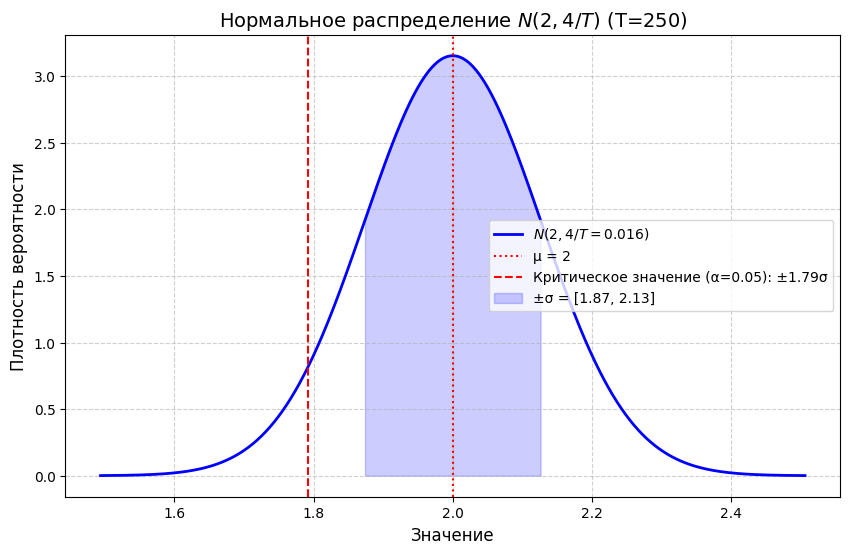

In [ ]:
mu = 2
T = 250
sigma2 = 4/T
sigma = np.sqrt(sigma2)
critical_value = norm.ppf(0.05, loc = 2, scale = np.sqrt(4/T))
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
pdf = norm.pdf(x, mu, sigma)
plt.figure(figsize=(10, 6))
plt.plot(x, pdf, 'b-', linewidth=2, label=f'$N(2, 4/T={sigma2:.3f})$')

# Настройка оформления
plt.title(f'Нормальное распределение $N(2, 4/T)$ (T={T})', fontsize=14)
plt.xlabel('Значение', fontsize=12)
plt.ylabel('Плотность вероятности', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=12)

# Вертикальная линия на среднем
plt.axvline(mu, color='red', linestyle=':', label=f'μ = {mu}')
plt.axvline(critical_value, color='red', linestyle='--',
            label=f'Критическое значение (α={0.05}): ±{critical_value:.2f}σ')

# Заполнение области под кривой
plt.fill_between(x, pdf, where=(x >= mu-sigma) & (x <= mu+sigma),
                 color='blue', alpha=0.2,
                 label=f'±σ = [{mu-sigma:.2f}, {mu+sigma:.2f}]')

plt.legend()
plt.show()

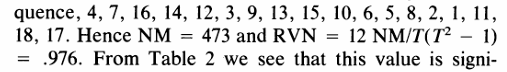

In [ ]:
x = [4, 7, 16, 14, 12, 3, 9, 13, 15, 10, 6, 5, 8, 2, 1, 11, 18, 17]
print(calculate_rvn(x))

0.9762641898864809
